# Publication figures — TROPOMI top-down wildfire CO & NO$_x$ emissions

Regenerates **all** main-text and SI figures for the ACS ES&T Air manuscript
directly from raw L2 data and saved MC/inventory/trajectory outputs.

**Do not trust the pre-existing PNGs in `paper_staging/figures/` — they are stale.**
This notebook overwrites them with current-pipeline numbers.

| Figure | Content | Source |
|--------|---------|--------|
| Fig 2  | NO$_x$ EMG fit + CO CSF transects | re-run (nb03 / nb02 logic) |
| Fig 3  | MC histograms + tornado, vs GFAS | `outputs/error_mc/`, `outputs/inventory_comparison/` |
| Fig 4  | ERA5 trajectory corridor          | `outputs/pathway/` + AER_AI |
| Fig 5  | HYSPLIT forward CO validation     | `outputs/hysplit_co/` + CO L2 |
| Fig S1 | GFAS radius sensitivity           | `outputs/inventory_comparison/` |
| Fig S2 | Injection-pressure distribution   | re-run (AER_LH↔AER_AI match) |

In [1]:
# ── Project root finder (walk up for data/ + src/), style, palette ──────────
import sys
from pathlib import Path

_p = Path.cwd().resolve()
ROOT = None
for cand in [_p, *_p.parents]:
    if (cand / "data").is_dir() and (cand / "src").is_dir():
        ROOT = cand
        break
assert ROOT is not None, "Could not locate project root (needs data/ + src/)."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

import glob
import json
import warnings
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely

from src import plume_helpers as ph

DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "outputs"
FIG_DIR  = ROOT / "paper_staging" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Shared publication style ───────────────────────────────────────────────
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
})

# ── Coherent palette ───────────────────────────────────────────────────────
C_CO    = "#4C78A8"   # steel blue   — CO
C_CO_E  = "#2A4D69"   # darker edge
C_NOX   = "#E1786E"   # coral/salmon — NOx
C_NOX_E = "#A83A30"
C_GFAS  = "#2CA02C"   # green        — GFAS inventory
C_CI    = "#7F7F7F"   # gray         — CI bounds
C_MED   = "#000000"   # black        — MC median

# ── Canonical case-study constants (CLAUDE.md, Jan 18 2026 lineage) ─────────
FIRE_LAT, FIRE_LON = -37.5484, -72.5545
# NOx reported on the NO mass basis (GFAS native basis); top-down EMG is native
# NO2 (gamma*M_NO2), so convert NO2->NO where top-down NOx is plotted.
NO2_TO_NO = 30.006 / 46.005   # 0.6522
TARGET_DAY = "0118"

# ── Shared L2 loader (all overpasses concatenated) and plume boundary ──────
# Replaces the previous ad hoc AI-threshold spatial clips
# (plume[160:, :] = False; np.where(lon > -72, clip(ai, 0, 1.99), ai)) with
# the hand-reviewed, DBSCAN-blob-clustered boundary from
# notebooks/plume_boundary_inspection.ipynb.
def load_and_concat(paths, loader, **kwargs):
    chunks = defaultdict(list)
    scalars = {}
    for pth in paths:
        pth = Path(pth)
        data = loader(pth, **kwargs)
        if data is None:
            continue  # skip orbits with no valid pixels in the ROI
        for k, v in data.items():
            if isinstance(v, np.ndarray):
                chunks[k].append(v)
            else:
                scalars[k] = v
    out = {k: np.concatenate(v) for k, v in chunks.items()}
    out.update(scalars)
    return out


PLUME_BOUNDARY_PATH = DATA_DIR / TARGET_DAY / "plume_boundary.geojson"
plume_boundary = ph.load_plume_boundary(PLUME_BOUNDARY_PATH)
AI_THRESHOLD = plume_boundary.threshold
print(f"Plume boundary: {plume_boundary.boundary.geom_type}  threshold={AI_THRESHOLD:.3f}  "
      f"[{PLUME_BOUNDARY_PATH.name}, created {plume_boundary.created_at}]")


def clip_ai_to_boundary(ai_data: dict) -> np.ndarray:
    """Clip AI below threshold outside the shared plume boundary."""
    in_boundary = shapely.contains_xy(plume_boundary.boundary, ai_data["lon"], ai_data["lat"])
    return np.where(in_boundary, ai_data["ai"], np.minimum(ai_data["ai"], AI_THRESHOLD - 1e-3))


def panel_label(ax, txt):
    ax.text(-0.02, 1.05, txt, transform=ax.transAxes,
            fontweight="bold", fontsize=12, va="bottom", ha="right")

print("Figures will be written to:", FIG_DIR)


Project root: /Users/maperezc/Downloads/wildfires


Plume boundary: MultiPolygon  threshold=2.000  [plume_boundary.geojson, created 2026-07-02T07:05:44.102192+00:00]
Figures will be written to: /Users/maperezc/Downloads/wildfires/paper_staging/figures


## Figure 2 — Emission retrievals

**(a)** NO$_x$ EMG fit (wind-rotated downwind line density) — re-runs the nb03 retrieval.
**(b)** CO CSF per-transect fluxes (AER_LH injection-height wind variant) — re-runs the nb02 retrieval.

Both panels rebuild the retrieval from raw TROPOMI L2 + ERA5 so the plotted data are
the current-pipeline values, not the stale saved PNGs.

In [2]:
# ── Fig 2(a) compute: NO2 EMG retrieval (nb03 logic) ───────────────────────
import h5py  # noqa: F401  (used inside loaders)
import xarray as xr
from scipy.optimize import curve_fit
from scipy.special import ndtr
from src.data_helpers import load_no2_l2, load_aer_ai, load_aer_lh
from src.wind_helpers import select_injection_pressure

# Constants (verbatim from nb03)
NO2_MOLAR_MASS_G_PER_MOL = 46.005
M_PER_DEG_LAT            = 111_320.0
NOX_NO2_RATIO_GAMMA      = 1.32
EARTH_RADIUS_KM          = 6371.0
EMG_EXTRACTION_RADIUS_KM = 450
CROSSWIND_INTEGRATION_KM = 100
DOWNWIND_MAX_KM, DOWNWIND_MIN_KM = 450.0, -100.0
GRID_DY_KM = 5.5
GRID_DY_M  = GRID_DY_KM * 1000.0
EMG_LAT_MIN, EMG_LAT_MAX = -46.83, -26.83
EMG_LON_MIN, EMG_LON_MAX = -83.05, -43.05
QA_UINT8     = 50

d18 = DATA_DIR / TARGET_DAY
NO2_PATH = sorted(glob.glob(str(d18 / "S5P_OFFL_L2__NO2____2026*")))
AER_AI_PATH = sorted(glob.glob(str(d18 / "S5P_OFFL_L2__AER_AI_2026*")))
AER_LH_PATH = sorted(glob.glob(str(d18 / "S5P_OFFL_L2__AER_LH_2026*")))

_box = dict(lat_min=EMG_LAT_MIN, lat_max=EMG_LAT_MAX,
            lon_min=EMG_LON_MIN, lon_max=EMG_LON_MAX, qa_threshold=QA_UINT8)
no2_data = load_and_concat(NO2_PATH, load_no2_l2, **_box)
ai_data  = load_and_concat(AER_AI_PATH, load_aer_ai, **_box)
# Plume boundary clip (shared plume_boundary/AI_THRESHOLD from setup cell),
# replacing the previous ad hoc "lon > -72" AI suppression.
ai_data["ai"] = clip_ai_to_boundary(ai_data)
alh_data = load_and_concat(AER_LH_PATH, load_aer_lh, **_box)

psel = select_injection_pressure(
    ai_raw=ai_data["ai"], ai_lat=ai_data["lat"], ai_lon=ai_data["lon"],
    alh_pres_raw=alh_data["alh_pres"], alh_lat=alh_data["lat"], alh_lon=alh_data["lon"],
    fire_lat=FIRE_LAT, fire_lon=FIRE_LON, ai_threshold=AI_THRESHOLD,
    radius_km=EMG_EXTRACTION_RADIUS_KM, min_pixels=0, aggregation="mean")
emg_pressure_hpa = psel["injection_pressure_hpa"]

# Overpass time at nearest pixel to fire. no2_data["time"] is per-pixel
# (see data_helpers.load_no2_l2), already positionally aligned with lat/lon
# — no scanline-index arithmetic (that was invalid once pixels are
# QA/domain-filtered and/or multiple overpasses are concatenated).
def _find_overpass(d, flat_fire_lat, flat_fire_lon):
    lats, lons, times = d["lat"], d["lon"], d["time"]
    dlat = lats - flat_fire_lat
    dlon = (lons - flat_fire_lon) * np.cos(np.radians(flat_fire_lat))
    k = int(np.argmin(dlat**2 + dlon**2))
    raw = times[k]
    if isinstance(raw, (bytes, np.bytes_)):
        raw = raw.decode("utf-8")
    return pd.Timestamp(raw).tz_localize(None)

OVERPASS_UTC = _find_overpass(no2_data, FIRE_LAT, FIRE_LON)

# ERA5 pressure-level wind at injection pressure (log-pressure interpolation)
era5 = xr.open_dataset(ROOT / "data" / "ERA5_winds_pressure_levels.nc")
tdim = "valid_time" if "valid_time" in era5.dims else "time"
era5_t = era5.sel({tdim: OVERPASS_UTC}, method="nearest")
latk = "latitude" if "latitude" in era5_t.coords else "lat"
lonk = "longitude" if "longitude" in era5_t.coords else "lon"
ila = int(np.argmin(np.abs(era5_t[latk].values - FIRE_LAT)))
ilo = int(np.argmin(np.abs(era5_t[lonk].values - FIRE_LON)))
u_prof = era5_t["u"].isel(**{latk: ila, lonk: ilo}).values.ravel()
v_prof = era5_t["v"].isel(**{latk: ila, lonk: ilo}).values.ravel()
p_lev  = era5_t["pressure_level"].values.ravel()
si = np.argsort(p_lev)
logp = np.log(p_lev[si])
U_WIND = float(np.interp(np.log(emg_pressure_hpa), logp, u_prof[si]))
V_WIND = float(np.interp(np.log(emg_pressure_hpa), logp, v_prof[si]))
WIND_SPEED = float(np.hypot(U_WIND, V_WIND))
THETA = float(np.arctan2(V_WIND, U_WIND))

# Extract NO2 within scene radius, rotate into wind frame, bin to grid
lat_d, lon_d, no2_d = no2_data["lat"], no2_data["lon"], no2_data["no2"]
phi0 = np.radians(FIRE_LAT)
a_hav = (np.sin((np.radians(lat_d) - phi0) / 2)**2
         + np.cos(phi0) * np.cos(np.radians(lat_d))
         * np.sin(np.radians(lon_d - FIRE_LON) / 2)**2)
dist_km = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a_hav, 0, 1)))
sm = (dist_km <= EMG_EXTRACTION_RADIUS_KM) & np.isfinite(no2_d)
lat_s, lon_s, no2_s = lat_d[sm], lon_d[sm], no2_d[sm]

m_per_deg_lon = M_PER_DEG_LAT * np.cos(np.radians(FIRE_LAT))
x_km = (lon_s - FIRE_LON) * m_per_deg_lon / 1000.0
y_km = (lat_s - FIRE_LAT) * M_PER_DEG_LAT / 1000.0
ct, st = np.cos(THETA), np.sin(THETA)
x_rot = x_km * ct + y_km * st
y_rot = -x_km * st + y_km * ct

half = GRID_DY_KM / 2.0
x_edges = np.arange(DOWNWIND_MIN_KM, DOWNWIND_MAX_KM + 1e-9, GRID_DY_KM)
y_edges = np.arange(-CROSSWIND_INTEGRATION_KM - half,
                    CROSSWIND_INTEGRATION_KM + half + 1e-9, GRID_DY_KM)
x_ctrs = 0.5 * (x_edges[:-1] + x_edges[1:])
y_ctrs = 0.5 * (y_edges[:-1] + y_edges[1:])
nx, ny = len(x_ctrs), len(y_ctrs)
ix = np.digitize(x_rot, x_edges) - 1
iy = np.digitize(y_rot, y_edges) - 1
vb = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)
gsum = np.zeros((nx, ny)); gcnt = np.zeros((nx, ny), int)
for k in np.where(vb)[0]:
    gsum[ix[k], iy[k]] += no2_s[k]; gcnt[ix[k], iy[k]] += 1
gmean = np.where(gcnt > 0, gsum / gcnt, np.nan).astype(np.float64)

dno2 = np.where(np.isfinite(gmean) & (gmean != 0), gmean, np.nan)
profile = np.nansum(np.where(np.isfinite(dno2), dno2, 0.0), axis=1) * GRID_DY_M  # mol m^-1
profile = np.where(np.any(np.isfinite(dno2), axis=1), profile, np.nan)

# EMG fit (Beirle 2011); 50-run median for stability (seed 42)
def emg(x, a, x0, mu_x, sigma_x, B):
    x = np.asarray(x, float); x0 = max(x0, 1e-6); sigma_x = max(sigma_x, 1e-6)
    expo = np.clip(mu_x/x0 + sigma_x**2/(2*x0**2) - x/x0, -500, 500)
    return (a/x0) * np.exp(expo) * ndtr((x - mu_x)/sigma_x - sigma_x/x0) + B

fm = np.isfinite(profile)
x_fit, y_fit = x_ctrs[fm], profile[fm]
ymax = float(np.nanmax(y_fit)); ymin = float(np.nanmin(y_fit))
xpk  = float(x_fit[np.argmax(y_fit)])
p0 = [ymax * 50.0, 50.0, xpk * 0.5, 30.0, ymin]
lo = [0.0, 1.0, -200.0, 1.0, -1e6]
hi = [np.inf, 500.0, 200.0, 200.0, max(ymax, 1.0)]
rng = np.random.default_rng(42)
fits = []
for _ in range(50):
    p0p = np.clip(np.array(p0) * rng.uniform(0.8, 1.2, 5), lo, hi)
    try:
        popt, _ = curve_fit(emg, x_fit, y_fit, p0=p0p, bounds=(lo, hi), maxfev=5000)
        if np.all(np.isfinite(popt)) and popt[0] > 0 and popt[1] > 0:
            fits.append(popt)
    except (RuntimeError, ValueError):
        continue
assert fits, "EMG fit failed to converge."
pmed = np.median(np.array(fits), axis=0)
a_md, x0_md, mu_md, sig_md, B_md = pmed
U_kph = WIND_SPEED * 3.6
tau_h = x0_md / U_kph
E_mol_s = (a_md / x0_md) * U_kph * 1000.0 / 3600.0
E_nox_g_s = E_mol_s * NOX_NO2_RATIO_GAMMA * NO2_MOLAR_MASS_G_PER_MOL
y_pred = emg(x_fit, *pmed)
ss_res = np.sum((y_fit - y_pred)**2)
ss_tot = np.sum((y_fit - np.mean(y_fit))**2)
emg_r2 = 1.0 - ss_res / ss_tot

print(f"EMG: injection p = {emg_pressure_hpa:.0f} hPa, U = {WIND_SPEED:.2f} m/s")
print(f"     a={a_md:.1f} mol/m, x0={x0_md:.1f} km, mu={mu_md:.1f} km, "
      f"sigma={sig_md:.1f} km, B={B_md:.2f} mol/m")
print(f"     tau={tau_h:.2f} h, E={E_nox_g_s:.0f} g/s, R2={emg_r2:.3f}")

[select_injection_pressure] AER_AI plume pixels (AI > 2.0): 2096
[select_injection_pressure] AER_LH pixels within 450 km of fire: 8034
[select_injection_pressure] AER_LH pixels matched to AI plume: 99
[select_injection_pressure] Pressure stats: mean=882 hPa, median=898 hPa, max=988 hPa, IQR=73 hPa


EMG: injection p = 882 hPa, U = 8.72 m/s
     a=374.5 mol/m, x0=23.6 km, mu=79.0 km, sigma=4.7 km, B=2.15 mol/m
     tau=0.75 h, E=8415 g/s, R2=0.846


/var/folders/0j/71sn2s2j71l6q088k8_ppzsc0000gn/T/ipykernel_31036/1153426333.py:108: RuntimeWarning: invalid value encountered in divide
  gmean = np.where(gcnt > 0, gsum / gcnt, np.nan).astype(np.float64)


In [3]:
# ── Fig 2(b) compute: CO CSF transect fluxes (nb02 logic, AER_LH variant) ──
from collections import defaultdict
from scipy.interpolate import RegularGridInterpolator
from src.data_helpers import load_co_l2
from src.csf_utils import (estimate_background, build_dynamic_transects,
                           compute_local_wind_direction, compute_csf_dynamic)

CO_MOLAR_MASS_KG_PER_MOL = 0.02801
CSF_LAT_MIN, CSF_LAT_MAX = -66.83, -6.83
CSF_LON_MIN, CSF_LON_MAX = -103.05, -43.05
CSF_GRID_KM = 4.0                 # 4 km cells at the fire latitude (Griffin et al. 2024)
CSF_OVERSAMPLE_RADIUS_KM = 7.0    # Adams et al. (2019) oversampling radius
CSF_SAMPLE_SPACING_M = CSF_GRID_KM * 1e3
CSF_EXTRACTION_RADIUS_KM = 450
N_TRANSECTS = 10
TRANSECT_HALF_WIDTH_KM = 100.0
BG_X_MIN_KM, BG_X_MAX_KM = -300.0, -200.0

_cbox = dict(lat_min=CSF_LAT_MIN, lat_max=CSF_LAT_MAX,
             lon_min=CSF_LON_MIN, lon_max=CSF_LON_MAX, qa_threshold=QA_UINT8)
co_files = sorted(d18.glob("S5P_OFFL_L2__CO_____*.nc"))
co_data = load_and_concat(co_files, load_co_l2, **_cbox, with_corners=True)
ai_csf  = load_and_concat(AER_AI_PATH, load_aer_ai, **_cbox, with_corners=True)
# Plume boundary clip (shared plume_boundary/AI_THRESHOLD), replacing the
# previous ad hoc "plume[160:, :] = False" northern clip.
ai_csf["ai"] = clip_ai_to_boundary(ai_csf)

# 4 km grid + Adams et al. (2019) oversampling of CO and AER_AI (as nb02)
from src.oversampling import regular_grid_km, oversample_to_grid
_csf_grid = regular_grid_km(CSF_LAT_MIN, CSF_LAT_MAX, CSF_LON_MIN, CSF_LON_MAX,
                            cell_km=CSF_GRID_KM, ref_lat=FIRE_LAT)
lat_c, lon_c = _csf_grid.lat, _csf_grid.lon
co_g, _ = oversample_to_grid(co_data["co"], co_data["lat_b"], co_data["lon_b"],
                             _csf_grid, CSF_OVERSAMPLE_RADIUS_KM)
ai_g, _ = oversample_to_grid(ai_csf["ai"].astype(np.float64), ai_csf["lat_b"], ai_csf["lon_b"],
                             _csf_grid, CSF_OVERSAMPLE_RADIUS_KM)
plume = (ai_g > AI_THRESHOLD) & np.isfinite(co_g)
# ai_csf["ai"] is already boundary-clipped, so `plume` is already
# boundary-consistent — no separate spatial clip needed here.

# ERA5 10 m surface wind -> plume-mean direction (for background x_rot frame)
overpass_h = 13.5 - FIRE_LON / 15.0  # TROPOMI 13:30 local solar crossing
OVP = pd.Timestamp("2026-01-18") + pd.Timedelta(hours=overpass_h)
with xr.open_dataset(ROOT / "data" / "ERA5_winds.nc") as ds:
    td = "valid_time" if "valid_time" in ds.dims else "time"
    dst = ds.sel({td: OVP}, method="nearest")
    s_lat, s_lon = dst["latitude"].values, dst["longitude"].values
    u10r, v10r = dst["u10"].values, dst["v10"].values
def _regrid(raw):
    fn = RegularGridInterpolator((s_lat[::-1], s_lon), raw[::-1],
                                 method="linear", bounds_error=False, fill_value=np.nan)
    lo_g, la_g = np.meshgrid(lon_c, lat_c)
    return fn(np.column_stack([la_g.ravel(), lo_g.ravel()])).reshape(len(lat_c), len(lon_c)).astype(np.float32)
u10, v10 = _regrid(u10r), _regrid(v10r)
_pw = plume & np.isfinite(u10)
theta_sfc = float(np.arctan2(float(v10[_pw].mean()), float(u10[_pw].mean())))

# CSF injection pressure (nb02 settings) + AER_LH-pressure wind
alh_csf = load_and_concat(AER_LH_PATH, load_aer_lh, **_cbox)
pcsf = select_injection_pressure(
    ai_raw=ai_csf["ai"], ai_lat=ai_csf["lat"], ai_lon=ai_csf["lon"],
    alh_pres_raw=alh_csf["alh_pres"], alh_lat=alh_csf["lat"], alh_lon=alh_csf["lon"],
    fire_lat=FIRE_LAT, fire_lon=FIRE_LON, ai_threshold=AI_THRESHOLD,
    radius_km=CSF_EXTRACTION_RADIUS_KM, min_pixels=20, aggregation="mean")
csf_pressure_hpa = pcsf["injection_pressure_hpa"]
era5_c = xr.open_dataset(ROOT / "data" / "ERA5_winds_pressure_levels.nc").sel({tdim: OVP}, method="nearest")
ila2 = int(np.argmin(np.abs(era5_c[latk].values - FIRE_LAT)))
ilo2 = int(np.argmin(np.abs(era5_c[lonk].values - FIRE_LON)))
up = era5_c["u"].isel(**{latk: ila2, lonk: ilo2}).values.ravel()
vp = era5_c["v"].isel(**{latk: ila2, lonk: ilo2}).values.ravel()
pl = era5_c["pressure_level"].values.ravel(); s2 = np.argsort(pl); lp2 = np.log(pl[s2])
u_alh = float(np.interp(np.log(csf_pressure_hpa), lp2, up[s2]))
v_alh = float(np.interp(np.log(csf_pressure_hpa), lp2, vp[s2]))
spd_alh = float(np.hypot(u_alh, v_alh))
u_alh_f = np.full_like(u10, u_alh); v_alh_f = np.full_like(v10, v_alh)

# Change-D background (far-upwind scalar median) -> delta CO
def _xrot(lat1, lon1, th):
    la0, lo0 = float(lat1.mean()), float(lon1.mean())
    lo_g, la_g = np.meshgrid(lon1, lat1)
    xm = (lo_g - lo0) * np.cos(np.radians(la0)) * M_PER_DEG_LAT
    ym = (la_g - la0) * M_PER_DEG_LAT
    return (xm * np.cos(th) + ym * np.sin(th)) / 1000.0
xr_km = _xrot(lat_c, lon_c, theta_sfc)
bgm = (xr_km >= BG_X_MIN_KM) & (xr_km <= BG_X_MAX_KM) & np.isfinite(co_g) & (co_g > 0)
assert bgm.sum() >= 10, "Change-D background window has <10 pixels."
bg_D = float(np.nanmedian(co_g[bgm]))
co_delta_D = co_g - bg_D

# Dynamic CSF — AER_LH injection-height wind variant (preferred).
# min_valid_fraction rejects transects with too few finite deltaCO samples
# (near-source pixel-coverage gaps).
MIN_VALID_FRACTION = 0.5   # accept a transect if > 50% of its samples are finite
slab_pos_var, t_flux_var, flux_var_kgs, _ = compute_csf_dynamic(
    co_delta_D, lat_c, lon_c, u_alh_f, v_alh_f, plume,
    n_transects=N_TRANSECTS, transect_half_width_km=TRANSECT_HALF_WIDTH_KM,
    sample_spacing_m=CSF_SAMPLE_SPACING_M, min_valid_fraction=MIN_VALID_FRACTION)
t_flux_var_kgs = t_flux_var * CO_MOLAR_MASS_KG_PER_MOL
slab_pos_km = np.asarray(slab_pos_var) / 1000.0
csf_valid = np.isfinite(t_flux_var_kgs)
n_csf_valid = int(csf_valid.sum())

print(f"CSF: injection p = {csf_pressure_hpa:.0f} hPa, U = {spd_alh:.2f} m/s")
print(f"     mean CO flux = {flux_var_kgs:.1f} kg/s, valid transects = {n_csf_valid}/{N_TRANSECTS}")

[select_injection_pressure] AER_AI plume pixels (AI > 2.0): 2096
[select_injection_pressure] AER_LH pixels within 450 km of fire: 8034
[select_injection_pressure] AER_LH pixels matched to AI plume: 99
[select_injection_pressure] Pressure stats: mean=882 hPa, median=898 hPa, max=988 hPa, IQR=73 hPa
CSF: injection p = 882 hPa, U = 8.72 m/s
     mean CO flux = 1363.3 kg/s, valid transects = 6/10


saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig2_emission_retrievals.png


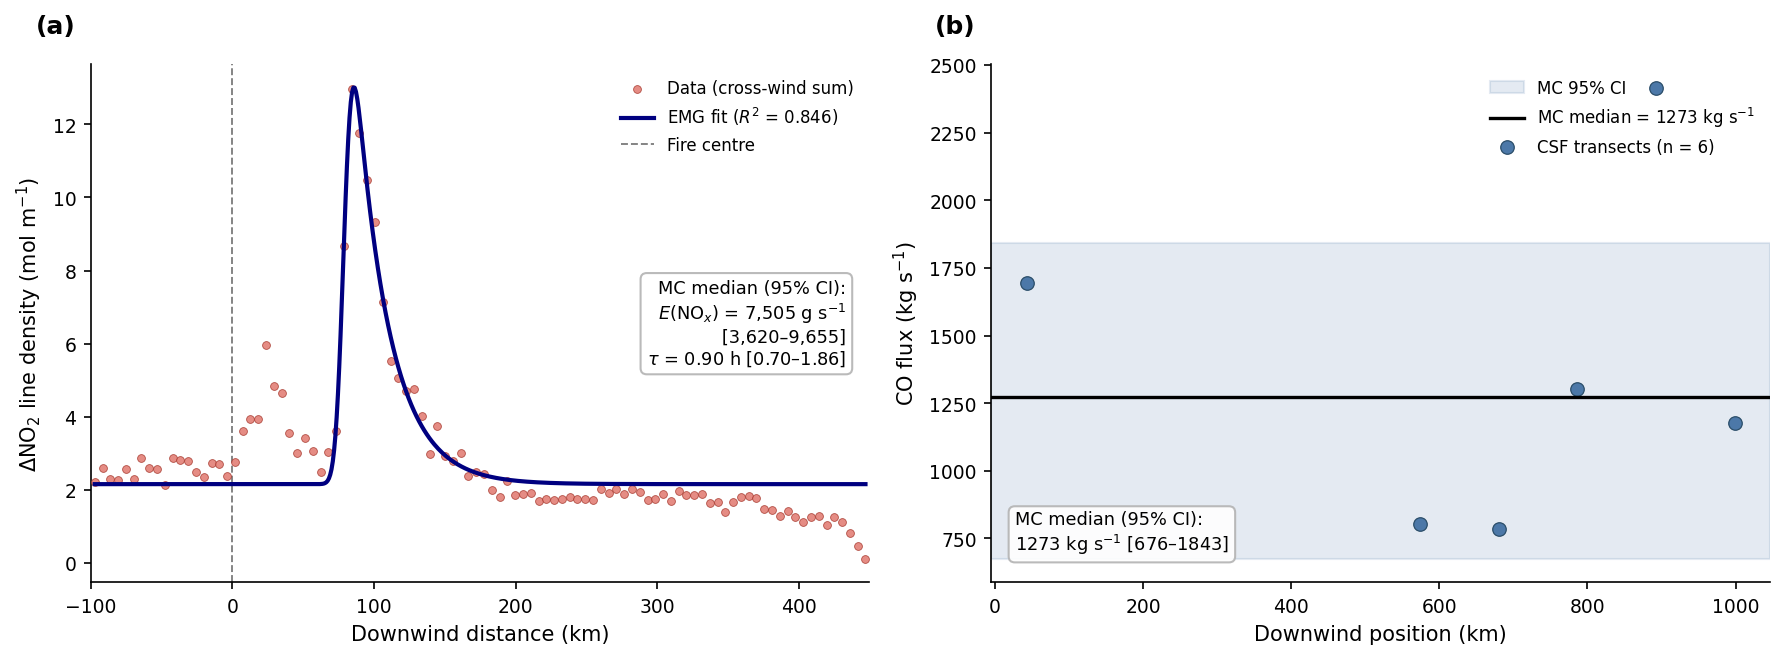

In [4]:
# ── Fig 2 figure: (a) EMG fit + (b) CSF transects (probabilistic headline) ──
# The paper's results are probabilistic (500-member Monte Carlo). The panels show
# the maximum-likelihood line-density fit (a) and the per-transect CSF fluxes (b)
# that feed the ensembles, but the headline numbers are the MC posteriors.
# NOx flux uncertainty is dominated by wind/pressure, not curve shape (the
# line-density amplitude a/x0 spans only ~13% across the ensemble vs -61/+27% for
# the flux), so panel (a) reports the posterior in the annotation rather than a
# misleadingly tight curve band; CO flux uncertainty maps onto the y-axis of (b)
# and is drawn as the MC median + 95% CI band. Full posteriors: Fig 3.
_mcdir = OUT_DIR / "error_mc" / TARGET_DAY
with open(_mcdir / "co_error_summary.json") as f:
    _co_s = json.load(f)["summary"]
with open(_mcdir / "nox_error_summary.json") as f:
    _nox_j = json.load(f)
_nox_s, _tau_s = _nox_j["E_nox"], _nox_j["tau"]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) EMG line-density fit; NOx flux/lifetime reported as MC posterior
xd = np.linspace(x_fit.min(), x_fit.max(), 600)
axa.scatter(x_fit, y_fit, s=14, color=C_NOX, edgecolor=C_NOX_E, linewidth=0.4,
            alpha=0.85, zorder=3, label="Data (cross-wind sum)")
axa.plot(xd, emg(xd, *pmed), "-", color="navy", lw=2,
         zorder=4, label=f"EMG fit ($R^2$ = {emg_r2:.3f})")
axa.axvline(0, color="gray", lw=0.9, ls="--", zorder=1, label="Fire centre")
axa.set_xlabel(r"Downwind distance (km)")
axa.set_ylabel(r"$\Delta$NO$_2$ line density (mol m$^{-1}$)")
axa.set_xlim(-100, 450)
axa.legend(loc="upper right", frameon=False)
axa.text(0.97, 0.585,
         "MC median (95% CI):\n"
         rf"$E$(NO$_x$) = {_nox_s['median']:,.0f} g s$^{{-1}}$" + "\n"
         rf"   [{_nox_s['p2_5']:,.0f}–{_nox_s['p97_5']:,.0f}]" + "\n"
         rf"$\tau$ = {_tau_s['median']:.2f} h [{_tau_s['p2_5']:.2f}–{_tau_s['p97_5']:.2f}]",
         transform=axa.transAxes, ha="right", va="top", fontsize=8.5,
         bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", alpha=0.9))
panel_label(axa, "(a)")

# (b) CSF per-transect fluxes with MC median + 95% CI band
axb.axhspan(_co_s["p2_5"], _co_s["p97_5"], color=C_CO, alpha=0.15, zorder=1,
            label="MC 95% CI")
axb.axhline(_co_s["median"], color=C_MED, lw=1.6, zorder=4,
            label=f"MC median = {_co_s['median']:.0f} kg s$^{{-1}}$")
axb.scatter(slab_pos_km[csf_valid], t_flux_var_kgs[csf_valid], s=42,
            color=C_CO, edgecolor=C_CO_E, linewidth=0.6, zorder=3,
            label=f"CSF transects (n = {n_csf_valid})")
axb.set_xlabel(r"Downwind position (km)")
axb.set_ylabel(r"CO flux (kg s$^{-1}$)")
axb.legend(loc="upper right", frameon=False)
axb.text(0.03, 0.05,
         "MC median (95% CI):\n"
         rf"{_co_s['median']:.0f} kg s$^{{-1}}$ "
         rf"[{_co_s['p2_5']:.0f}–{_co_s['p97_5']:.0f}]",
         transform=axb.transAxes, ha="left", va="bottom", fontsize=8.5,
         bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", alpha=0.9))
panel_label(axb, "(b)")

fig.tight_layout()
_out = FIG_DIR / "fig2_emission_retrievals.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

## Figure 3 — Monte-Carlo uncertainty and GFAS comparison

2×2: CO/NO$_x$ MC flux histograms (top) and variance-decomposition tornado plots (bottom),
read from `outputs/error_mc/0118/`. GFAS overpass-matched values overlaid in red.

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig3_mc_gfas.png


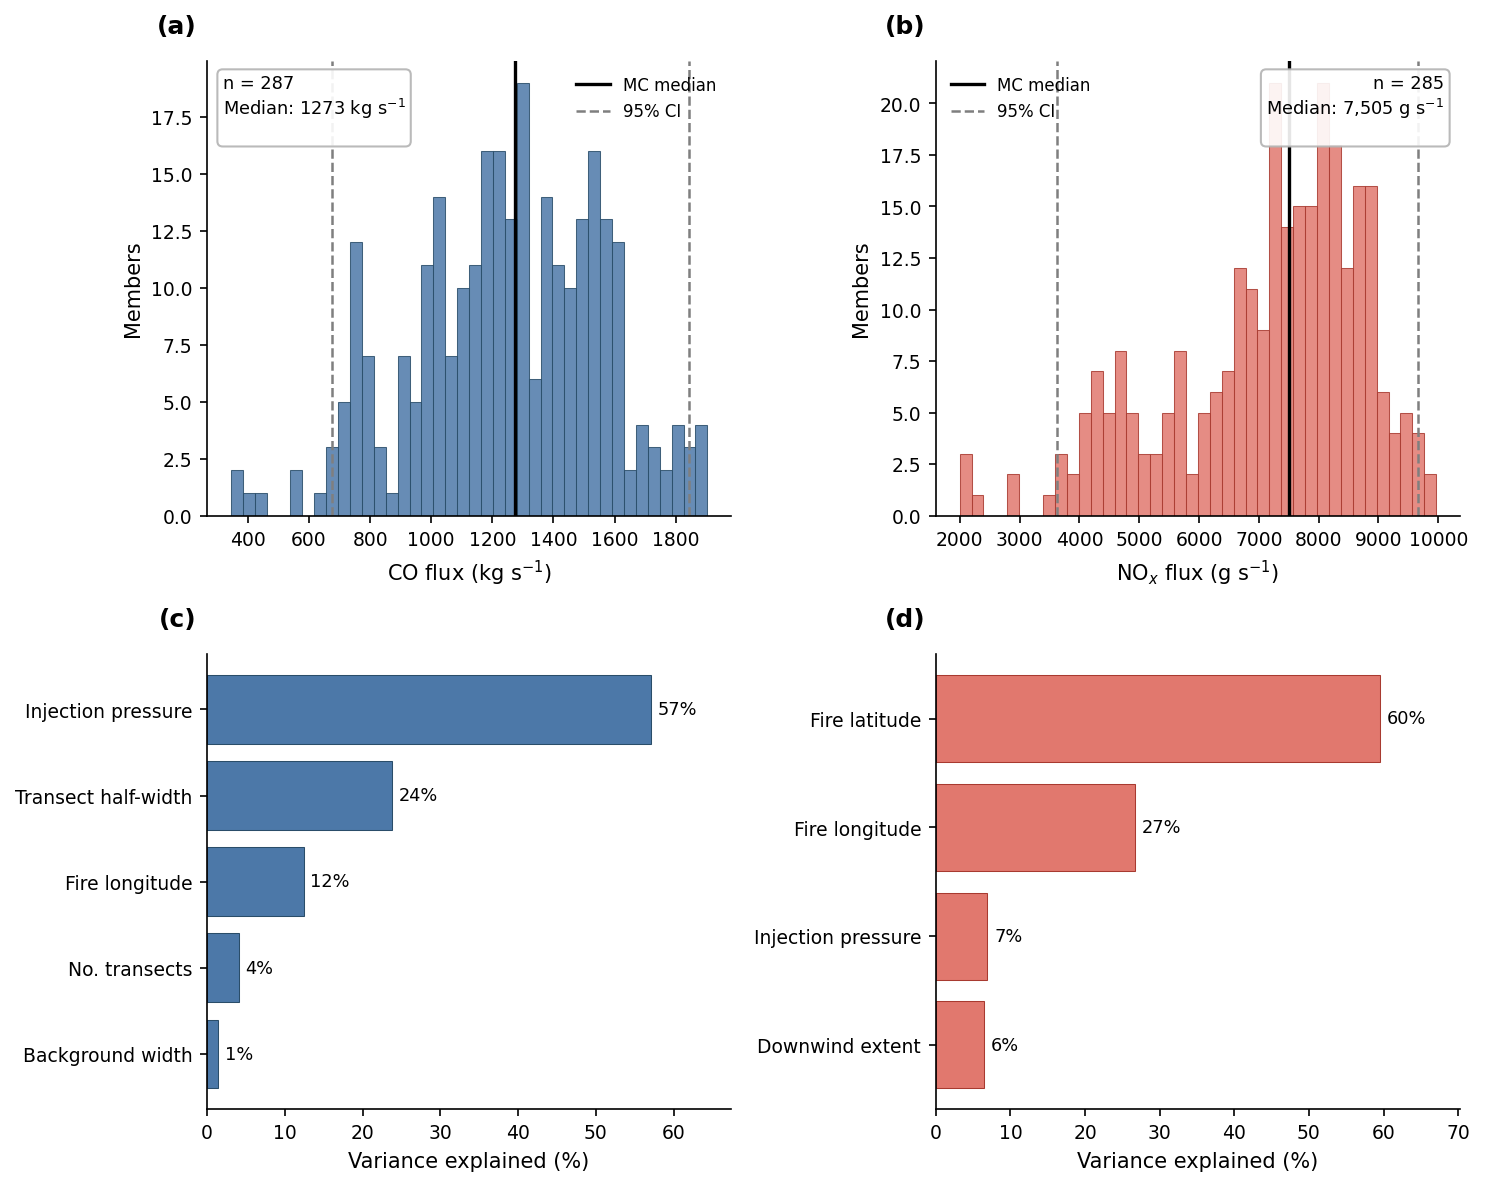

In [5]:
# ── Fig 3: load MC outputs ─────────────────────────────────────────────────
MC = OUT_DIR / "error_mc" / TARGET_DAY
co_mem  = pd.read_csv(MC / "co_error_members.csv")
nox_mem = pd.read_csv(MC / "nox_error_members.csv")
co_tor  = pd.read_csv(MC / "co_error_tornado.csv")
nox_tor = pd.read_csv(MC / "nox_error_tornado_E.csv")
with open(MC / "co_error_summary.json") as f:
    co_sum = json.load(f)["summary"]
with open(MC / "nox_error_summary.json") as f:
    nox_sum = json.load(f)["E_nox"]   # raw NO2 basis; convert NO2->NO at each use

co_flux  = co_mem["flux_kgs"].dropna().to_numpy()
nox_flux = nox_mem["E_nox_g_per_s"].dropna().to_numpy()   # NO2 basis (native EMG; results)

# GFAS NOx converted NO->NO2 basis (x46.005/30.006) to match top-down (nb03/nb04).
GFAS_CO, GFAS_NOX = 331.89, 10871.34       # overpass-matched, R99 (nb04); NOx native NO basis
GFAS_CO_PCTL, GFAS_NOX_PCTL = 2.1, 100.0   # nb09 comparison_mc_summary

LABELS = {
    "pressure_hpa": "Injection pressure", "fire_lon": "Fire longitude",
    "fire_lat": "Fire latitude", "n_transects": "No. transects",
    "extraction_radius_km": "Extraction radius", "downwind_max_km": "Downwind extent",
    "transect_half_width_km": "Transect half-width", "bg_width_km": "Background width",
    "bg_x_min_km": "Background position",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
(ax_a, ax_b), (ax_c, ax_d) = axes

# (a) CO histogram — bin count + 99th-pct clipping matched to nb07's own figure
co_q99 = np.percentile(co_flux, 99)
ax_a.hist(co_flux[co_flux <= co_q99], bins=40, color=C_CO, edgecolor=C_CO_E, linewidth=0.5, alpha=0.85)
ax_a.axvline(co_sum["median"], color=C_MED, lw=1.6, label="MC median")
ax_a.axvline(co_sum["p2_5"],  color=C_CI, lw=1.2, ls="--", label="95% CI")
ax_a.axvline(co_sum["p97_5"], color=C_CI, lw=1.2, ls="--")
#ax_a.axvline(GFAS_CO, color=C_GFAS, lw=2.0, label="GFAS @R99")
ax_a.set_xlabel(r"CO flux (kg s$^{-1}$)"); ax_a.set_ylabel("Members")
ax_a.legend(loc="upper right", frameon=False)
ax_a.text(0.03, 0.97, f"n = {co_sum['n']}\nMedian: {co_sum['median']:.0f} kg s$^{{-1}}$\n", 
          transform=ax_a.transAxes, va="top", ha="left",
          fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
panel_label(ax_a, "(a)")

# (b) NOx histogram — bin count + 99th-pct clipping matched to nb08's own figure
nox_q99 = np.percentile(nox_flux, 99)
ax_b.hist(nox_flux[nox_flux <= nox_q99], bins=40, color=C_NOX, edgecolor=C_NOX_E, linewidth=0.5, alpha=0.85)
ax_b.axvline(nox_sum["median"], color=C_MED, lw=1.6, label="MC median")
ax_b.axvline(nox_sum["p2_5"],  color=C_CI, lw=1.2, ls="--", label="95% CI")
ax_b.axvline(nox_sum["p97_5"], color=C_CI, lw=1.2, ls="--")
#ax_b.axvline(GFAS_NOX, color=C_GFAS, lw=2.0, label="GFAS @R99")
ax_b.set_xlabel(r"NO$_x$ flux (g s$^{-1}$)"); ax_b.set_ylabel("Members")
ax_b.legend(loc="upper left", frameon=False)
ax_b.text(0.97, 0.97, f"n = {nox_sum['n']}\nMedian: {nox_sum['median']:,.0f} g s$^{{-1}}$\n",
          transform=ax_b.transAxes, va="top", ha="right",
          fontsize=8.5, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
panel_label(ax_b, "(b)")

def _tornado(ax, tor, color, edge):
    t = tor[tor["var_share_pct"] > 1.0].copy()
    t = t.sort_values("var_share_pct", ascending=True)
    names = [LABELS.get(p, p) for p in t["parameter"]]
    y = np.arange(len(t))
    ax.barh(y, t["var_share_pct"], color=color, edgecolor=edge, linewidth=0.5)
    ax.set_yticks(y); ax.set_yticklabels(names)
    ax.set_xlabel("Variance explained (%)")
    xmax = float(t["var_share_pct"].max())
    ax.set_xlim(0, xmax * 1.18)
    for yi, val in zip(y, t["var_share_pct"]):
        ax.text(val + xmax * 0.015, yi, f"{val:.0f}%", va="center", ha="left", fontsize=8.5)

# (c) CO tornado
_tornado(ax_c, co_tor, C_CO, C_CO_E); panel_label(ax_c, "(c)")
# (d) NOx tornado
_tornado(ax_d, nox_tor[nox_tor["parameter"] != "grid_dy_deg"], C_NOX, C_NOX_E)
panel_label(ax_d, "(d)")

fig.tight_layout()
_out = FIG_DIR / "fig3_mc_gfas.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

## Figure 4 — ERA5 trajectory ensemble corridor

500-member ERA5 isobaric trajectory corridor (visit probability) with the observed
AER_AI plume (AI > 2.0) from the four following overpasses overlaid, fire centroid and
MODIS Aqua detections marked. Cartopy `PlateCarree` projection with coastlines.

  [0120] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).
  [0121] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).


saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig4_trajectory_corridor.png | cartopy: True


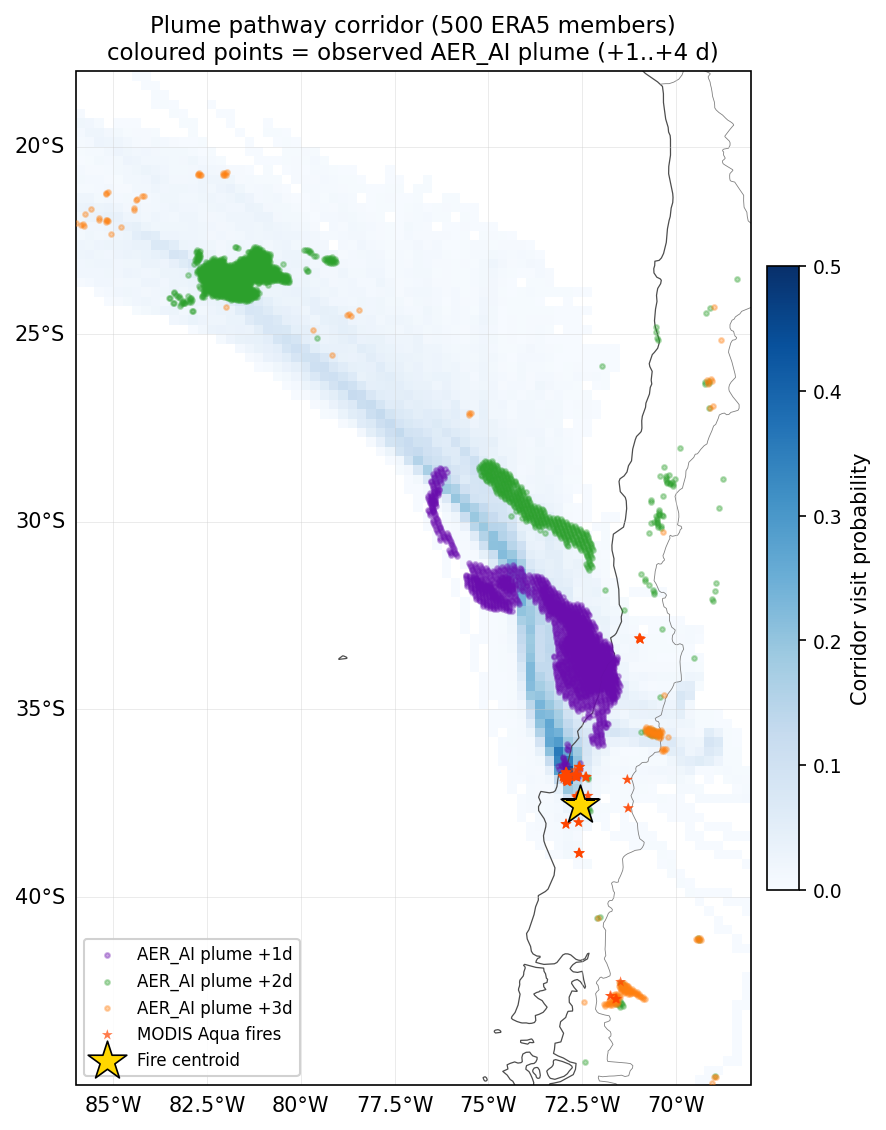

In [6]:
# ── Fig 4: trajectory corridor + observed AER_AI overlay ───────────────────
from src.fire_clustering import load_modis_csv

PW = OUT_DIR / "pathway"
corridor = np.load(PW / "corridor_prob.npy")
lat_edges = np.load(PW / "lat_edges.npy")
lon_edges = np.load(PW / "lon_edges.npy")

OVERPASSES = [("0119", 1, "#6a0dad"), ("0120", 2, "#2ca02c"),
              ("0121", 3, "#ff7f0e"), ("0122", 4, "#e6c700")]
EXT = [-86, -68, -45, -18]  # lon_min, lon_max, lat_min, lat_max

def _ai_plume(folder):
    """AER_AI plume pixels for a validation date (all overpasses concatenated).

    Uses the saved plume boundary where one exists (0118, 0119); other
    validation dates (0120-0122) have no hand-reviewed boundary yet, so this
    falls back to the raw AI_THRESHOLD test with no spatial gate — printed so
    it's visible which dates are ungated.
    """
    fs = sorted((DATA_DIR / folder).glob("S5P_OFFL_L2__AER_AI_2026*.nc"))
    if not fs:
        return None
    a = load_and_concat(fs, load_aer_ai, lat_min=EXT[2], lat_max=EXT[3],
                        lon_min=EXT[0], lon_max=EXT[1], qa_threshold=50)
    boundary_path = DATA_DIR / folder / "plume_boundary.geojson"
    if boundary_path.is_file():
        _b = ph.load_plume_boundary(boundary_path)
        _in_b = shapely.contains_xy(_b.boundary, a["lon"], a["lat"])
        m = _in_b & (a["ai"] > _b.threshold) & np.isfinite(a["ai"])
    else:
        print(f"  [{folder}] no plume_boundary.geojson — using raw AI > {AI_THRESHOLD} "
              f"with no spatial gate (ungated).")
        m = (a["ai"] > AI_THRESHOLD) & np.isfinite(a["ai"])
    return (a["lon"][m], a["lat"][m]) if m.sum() >= 5 else None

fires = load_modis_csv(DATA_DIR / "fire_nrt_M-C61_723973.csv",
                       pd.Timestamp("2026-01-18"), pd.Timestamp("2026-01-18"),
                       lat_min=EXT[2], lat_max=EXT[3], lon_min=EXT[0], lon_max=EXT[1],
                       min_confidence=75, daytime_only=True, satellite="Aqua")

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY = True
except Exception:
    _HAS_CARTOPY = False

if _HAS_CARTOPY:
    proj = ccrs.PlateCarree()
    fig = plt.figure(figsize=(7, 9))
    ax = plt.axes(projection=proj)
    ax.set_extent(EXT, crs=proj)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6, edgecolor="0.3")
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.4, edgecolor="0.5")
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="0.8", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    _tr = dict(transform=proj)
else:
    fig, ax = plt.subplots(figsize=(7, 9))
    ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3])
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    _tr = {}

pm = ax.pcolormesh(lon_edges, lat_edges, np.where(corridor > 0, corridor, np.nan),
                   cmap="Blues", vmin=0, vmax=max(0.5, float(corridor.max())),
                   shading="flat", **_tr)
cb = fig.colorbar(pm, ax=ax, shrink=0.6, pad=0.02)
cb.set_label("Corridor visit probability")

for folder, off, col in OVERPASSES:
    obs = _ai_plume(folder)
    if obs is not None:
        ax.scatter(obs[0], obs[1], s=5, c=col, alpha=0.35, zorder=6,
                   label=f"AER_AI plume +{off}d", **_tr)
ax.scatter(fires["longitude"], fires["latitude"], marker="*", s=30, c="orangered",
           edgecolors="none", alpha=0.7, zorder=7, label="MODIS Aqua fires", **_tr)
ax.scatter(FIRE_LON, FIRE_LAT, marker="*", s=380, c="gold", edgecolors="k",
           linewidth=0.8, zorder=10, label="Fire centroid", **_tr)
if not _HAS_CARTOPY:
    ax.set_aspect("equal")
ax.set_title("Plume pathway corridor (500 ERA5 members)\n"
             "coloured points = observed AER_AI plume (+1..+4 d)", fontsize=11)
ax.legend(loc="lower left", fontsize=8, framealpha=0.9)

_out = FIG_DIR / "fig4_trajectory_corridor.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out, "| cartopy:", _HAS_CARTOPY)
plt.show()

## Figure 5 — HYSPLIT forward CO validation

HYSPLIT-CONC forward run driven by the MC-median CO flux (838 kg s$^{-1}$). Observed TROPOMI
CO column enhancement (pcolormesh) with modeled CO column contours (navy, 50/90th pct) for
+1 d … +4 d. cdump read via `hysplit_helpers.read_cdump` (NumPy-2 patched).

HYSPLIT cdump driven by 1273.3 kg/s (CONTROL); current MC median 1273.3 kg/s


Please install s3fs if retrieving from the Amazon S3 Servers.  Otherwise continue with local data
Please install h5netcdf to open files from the Amazon S3 servers.


/Users/maperezc/Downloads/env/lib/python3.13/site-packages/monetio/models/hysplit.py:623: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  self.dset = xr.merge([self.dset, dset])
/Users/maperezc/Downloads/env/lib/python3.13/site-packages/monetio/models/hysplit.py:623: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'y' ('y',) The recommendation is to set join explicitly for this case.
  self.dset = xr.merge([self.dset, dset])
/Users/maperez

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig5_hysplit_forward.png


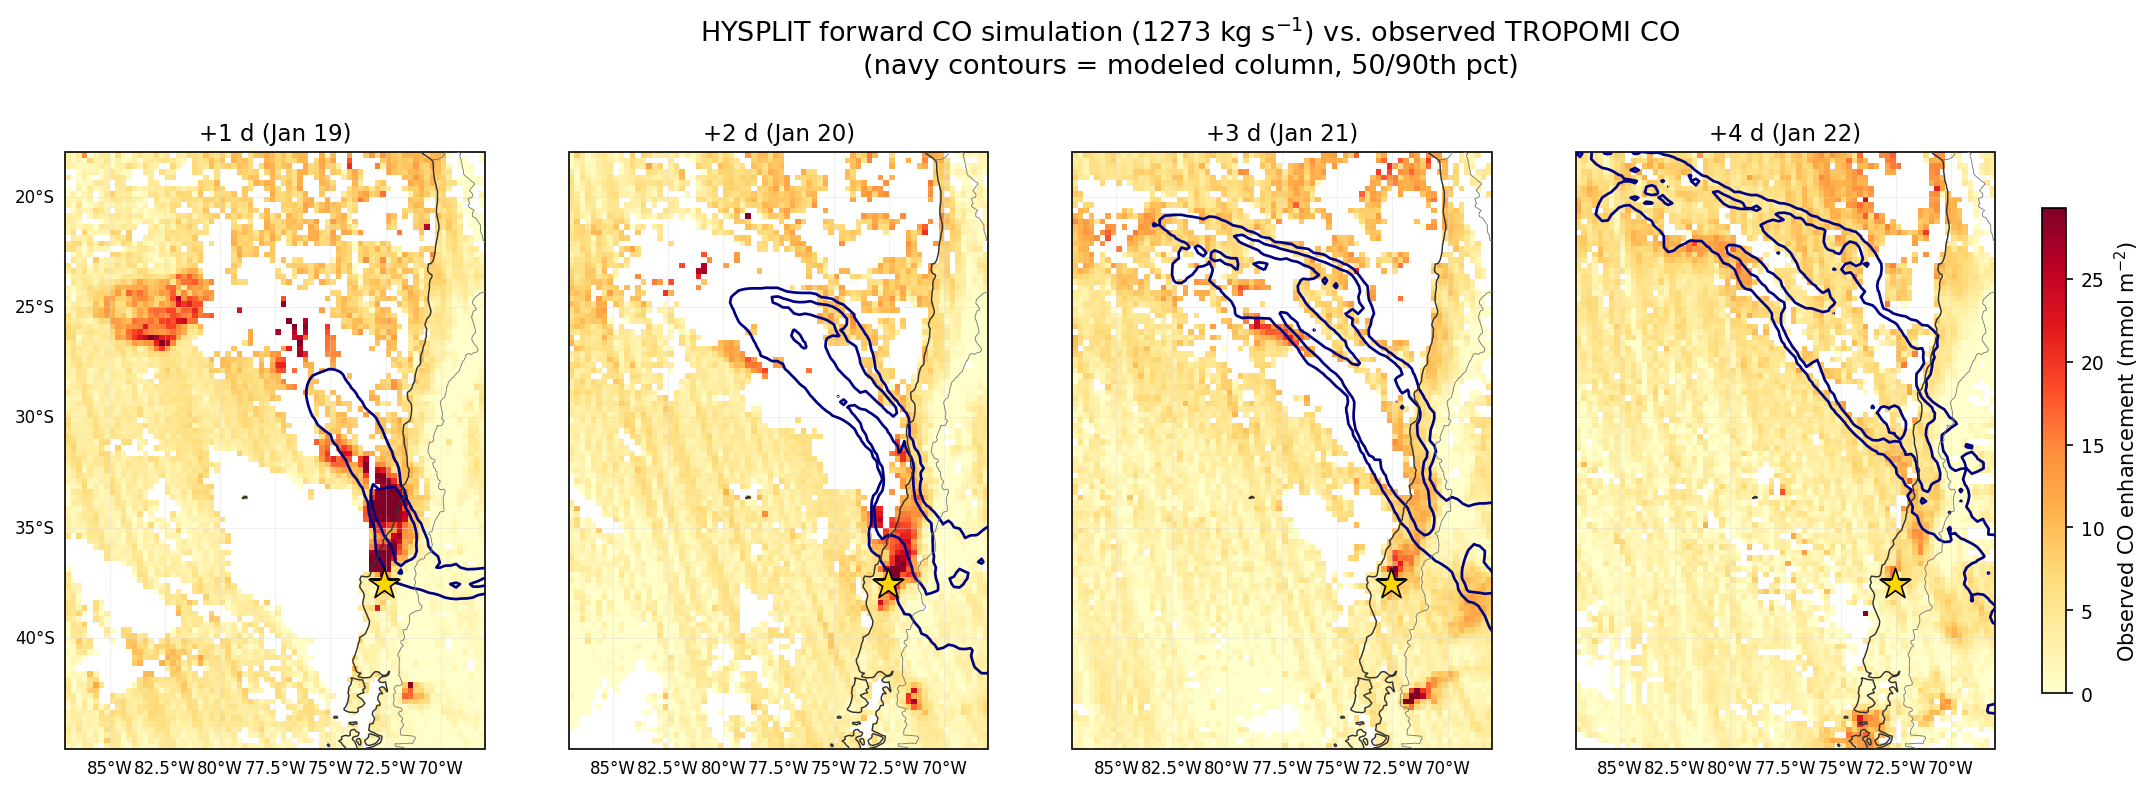

In [7]:
# ── Fig 5: HYSPLIT modeled column contours over observed CO enhancement ────
import src.hysplit_helpers as H
from src.data_helpers import load_co_l2

CO_MOLAR_MASS_KG = 0.02801
RUN_DIR = OUT_DIR / "hysplit_co" / "run_0118"
LAT_MIN, LAT_MAX = -45.0, -18.0
LON_MIN, LON_MAX = -87.0, -68.0
GRID_RES = 0.25
BG_PERCENTILE  = 10.0
MOD_COL_THRESH = 1.0e-4
LEVEL_TOP_M    = 6000.0
# Label with the emission rate that actually drove this cdump (HYSPLIT CONTROL,
# kg/hr on the line after the pollutant id), not the current MC median: the
# cdump is cached and is not re-run when the CO posterior changes.
_ctl = (RUN_DIR / "CONTROL").read_text().splitlines()
CO_FLUX_KGS = float(_ctl[_ctl.index("CO") + 1]) / 3600.0
print(f"HYSPLIT cdump driven by {CO_FLUX_KGS:.1f} kg/s (CONTROL); current MC median "
      f"{float(co_sum['median']):.1f} kg/s")

OVP5 = [("0119", 1, pd.Timestamp("2026-01-19 18:57"), "+1 d (Jan 19)"),
        ("0120", 2, pd.Timestamp("2026-01-20 18:39"), "+2 d (Jan 20)"),
        ("0121", 3, pd.Timestamp("2026-01-21 18:20"), "+3 d (Jan 21)"),
        ("0122", 4, pd.Timestamp("2026-01-22 18:01"), "+4 d (Jan 22)")]

ds = H.read_cdump(RUN_DIR / "cdump")
col_mol = H.cdump_to_column(ds, "CO", level_thickness_m=LEVEL_TOP_M) / CO_MOLAR_MASS_KG
mod_lon = np.asarray(ds.longitude.values, float)
mod_lat = np.asarray(ds.latitude.values, float)
mod_times = pd.to_datetime(ds.time.values)

lat_edges5 = np.arange(LAT_MIN, LAT_MAX + GRID_RES, GRID_RES)
lon_edges5 = np.arange(LON_MIN, LON_MAX + GRID_RES, GRID_RES)
lat_ctrs5 = 0.5 * (lat_edges5[:-1] + lat_edges5[1:])
lon_ctrs5 = 0.5 * (lon_edges5[:-1] + lon_edges5[1:])

def _bin_co(folder):
    fs = sorted((DATA_DIR / folder).glob("S5P_OFFL_L2__CO_____*.nc"))
    if not fs:
        return None
    from collections import defaultdict
    cc = defaultdict(list)
    for f in fs:
        c = load_co_l2(f, lat_min=LAT_MIN, lat_max=LAT_MAX,
                       lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=50)
        for k in ("co", "lat", "lon"):
            cc[k].append(c[k])
    cof = np.concatenate(cc["co"]); la = np.concatenate(cc["lat"]); lo = np.concatenate(cc["lon"])
    g = np.full((len(lat_ctrs5), len(lon_ctrs5)), np.nan)
    il = np.searchsorted(lat_edges5[1:-1], la); jl = np.searchsorted(lon_edges5[1:-1], lo)
    ok = np.isfinite(cof)
    df = pd.DataFrame({"v": cof[ok], "i": il[ok], "j": jl[ok]})
    for (i, j), v in df.groupby(["i", "j"])["v"].mean().items():
        g[i, j] = v
    return g

obs_grids = {off: _bin_co(folder) for folder, off, _, _ in OVP5}

# shared colour scale across panels
_enh_max = max(np.nanpercentile((obs_grids[o] - np.nanpercentile(obs_grids[o], BG_PERCENTILE)) * 1e3, 99)
               for _, o, _, _ in OVP5 if obs_grids[o] is not None)
_enh_max = max(2.0, float(_enh_max))

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY = True
except Exception:
    _HAS_CARTOPY = False

if _HAS_CARTOPY:
    proj = ccrs.PlateCarree()
    fig, axes = plt.subplots(1, 4, figsize=(20, 6), subplot_kw={"projection": proj})
    _tr = dict(transform=proj)
else:
    fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharex=True, sharey=True)
    _tr = {}

pm = None
for i, (ax, (folder, off, dt, title)) in enumerate(zip(axes, OVP5)):
    g = obs_grids[off]
    if g is not None:
        bg = np.nanpercentile(g, BG_PERCENTILE)
        pm = ax.pcolormesh(lon_edges5, lat_edges5, (g - bg) * 1e3, cmap="YlOrRd",
                           vmin=0, vmax=_enh_max, shading="flat", zorder=2, **_tr)
    k = int(np.argmin(np.abs(mod_times - dt)))
    mf = np.asarray(col_mol.isel(time=k).values)
    if (mf > MOD_COL_THRESH).any():
        ax.contour(mod_lon, mod_lat, mf,
                   levels=np.nanpercentile(mf[mf > 0], [50, 90]),
                   colors="navy", linewidths=1.3, zorder=4, **_tr)
    ax.scatter(FIRE_LON, FIRE_LAT, marker="*", s=240, c="gold",
               edgecolors="k", linewidth=0.8, zorder=10, **_tr)
    if _HAS_CARTOPY:
        # Continent coastlines + national borders so plumes map onto the globe
        ax.add_feature(cfeature.COASTLINE.with_scale("50m"),
                       linewidth=0.7, edgecolor="0.2", zorder=5)
        ax.add_feature(cfeature.BORDERS.with_scale("50m"),
                       linewidth=0.4, edgecolor="0.45", zorder=5)
        ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="0.85", alpha=0.6)
        gl.top_labels = gl.right_labels = False
        gl.left_labels = (i == 0)
        gl.xlabel_style = {"size": 8}
        gl.ylabel_style = {"size": 8}
    else:
        ax.set_xlim(LON_MIN, LON_MAX); ax.set_ylim(LAT_MIN, LAT_MAX)
        ax.set_xlabel("Longitude")
        if i == 0:
            ax.set_ylabel("Latitude")
    ax.set_title(title, fontsize=11)

if pm is not None:
    cb = fig.colorbar(pm, ax=axes, shrink=0.7, pad=0.02)
    cb.set_label(r"Observed CO enhancement (mmol m$^{-2}$)")
fig.suptitle(f"HYSPLIT forward CO simulation ({CO_FLUX_KGS:.0f} kg s$^{{-1}}$) "
             "vs. observed TROPOMI CO\n(navy contours = modeled column, 50/90th pct)",
             fontsize=13)
_out = FIG_DIR / "fig5_hysplit_forward.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

## Figure S1 — GFAS radius sensitivity

GFAS CO and NO$_x$ integrated flux vs. integration radius, compared to the top-down MC
posterior (median ± 95% CI band). R99 = 142 km marked.

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/figS1_radius_sensitivity.png


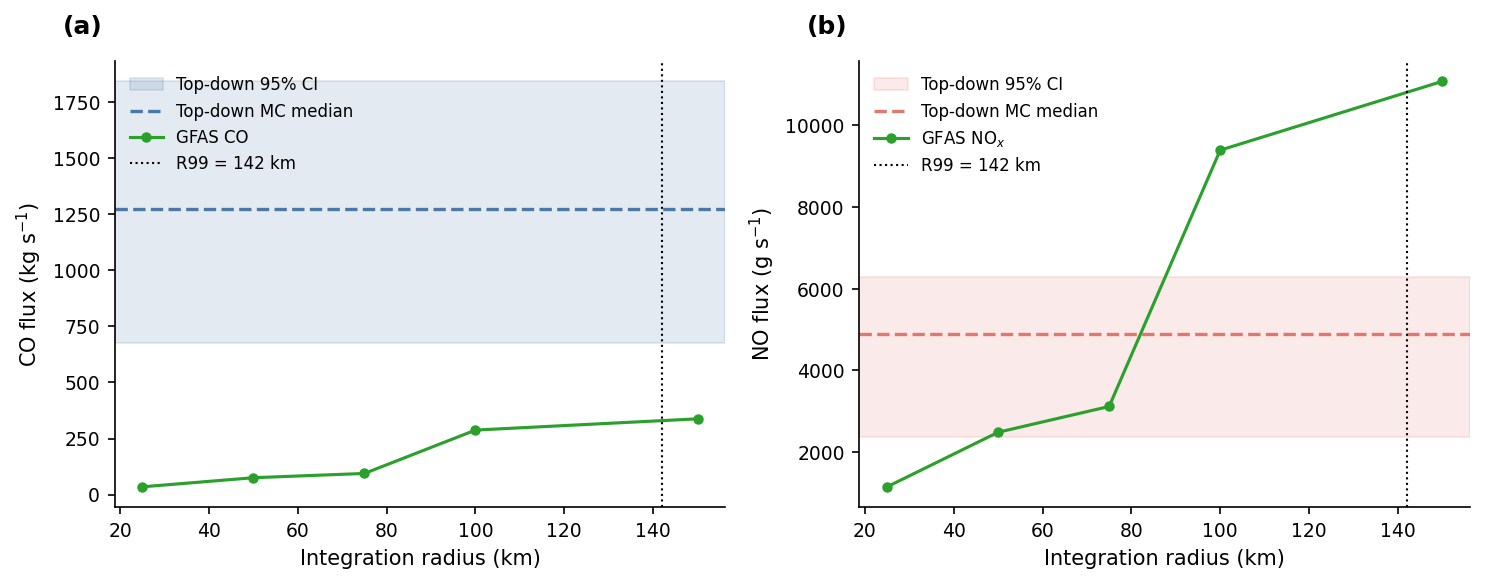

In [8]:
# ── Fig S1: GFAS radius sensitivity vs top-down MC band ────────────────────
rs = pd.read_csv(OUT_DIR / "inventory_comparison" / TARGET_DAY / "radius_sensitivity.csv")
R99 = 142.0

CO_MED, CO_LO, CO_HI    = co_sum["median"], co_sum["p2_5"], co_sum["p97_5"]
NOX_MED, NOX_LO, NOX_HI = (nox_sum["median"]*NO2_TO_NO, nox_sum["p2_5"]*NO2_TO_NO, nox_sum["p97_5"]*NO2_TO_NO)   # NO basis

fig, (axa, axb) = plt.subplots(1, 2, figsize=(10, 4))

# (a) CO
axa.axhspan(CO_LO, CO_HI, color=C_CO, alpha=0.15, label="Top-down 95% CI")
axa.axhline(CO_MED, color=C_CO, lw=1.6, ls="--", label="Top-down MC median")
axa.plot(rs["radius_km"], rs["gfas_co_kg_s"], "-o", color=C_GFAS, ms=4, lw=1.5, label="GFAS CO")
axa.axvline(R99, color=C_MED, lw=1.0, ls=":", label="R99 = 142 km")
axa.set_xlabel("Integration radius (km)")
axa.set_ylabel(r"CO flux (kg s$^{-1}$)")
axa.legend(loc="upper left", frameon=False)
panel_label(axa, "(a)")

# (b) NOx
axb.axhspan(NOX_LO, NOX_HI, color=C_NOX, alpha=0.15, label="Top-down 95% CI")
axb.axhline(NOX_MED, color=C_NOX, lw=1.6, ls="--", label="Top-down MC median")
axb.plot(rs["radius_km"], rs["gfas_nox_g_s"], "-o", color=C_GFAS, ms=4, lw=1.5, label="GFAS NO$_x$")
axb.axvline(R99, color=C_MED, lw=1.0, ls=":", label="R99 = 142 km")
axb.set_xlabel("Integration radius (km)")
axb.set_ylabel(r"NO flux (g s$^{-1}$)")
axb.legend(loc="upper left", frameon=False)
panel_label(axb, "(b)")

fig.tight_layout()
_out = FIG_DIR / "figS1_radius_sensitivity.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

## Figure S2 — Injection-pressure distribution

Histogram + Gaussian-KDE (Scott bandwidth) of AER_LH aerosol mid-pressure matched to the
AER_AI plume (AI > 2.0, 450 km radius). This is the injection-pressure prior used in the MC.

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/figS2_injection_pressure.png | n matched = 99 median = 898


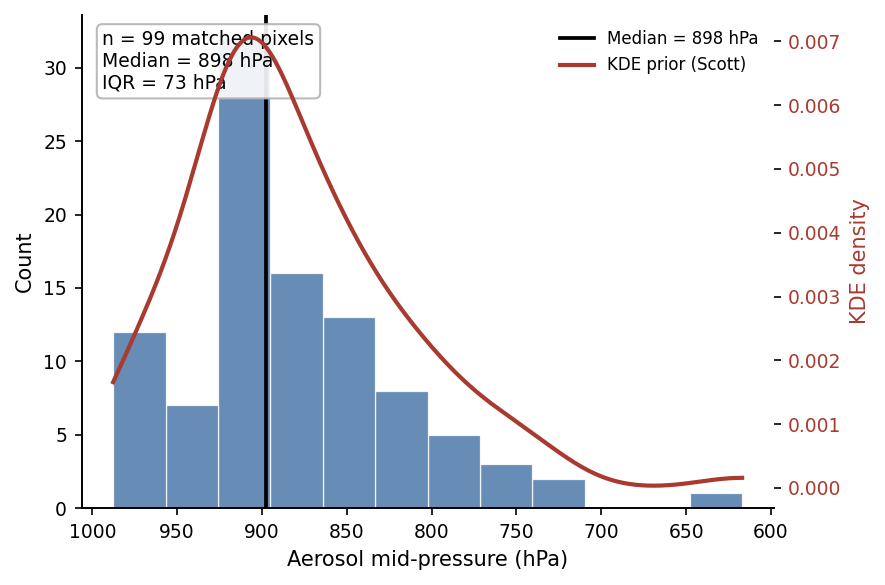

In [9]:
# ── Fig S2: injection-pressure distribution + KDE prior ────────────────────
# Reuse the exact AER_AI/AER_LH arrays from the Fig 2(a) injection-pressure
# selection (EMG box + east-of-72W AI suppression) so the distribution matches
# the 900 hPa / 107-pixel injection pressure used by both retrievals and the MC.
from scipy.stats import gaussian_kde
from src.wind_helpers import match_alh_plume_pressures

match = match_alh_plume_pressures(
    ai_raw=ai_data["ai"], ai_lat=ai_data["lat"], ai_lon=ai_data["lon"],
    alh_pres_raw=alh_data["alh_pres"], alh_lat=alh_data["lat"], alh_lon=alh_data["lon"],
    fire_lat=FIRE_LAT, fire_lon=FIRE_LON, ai_threshold=AI_THRESHOLD, radius_km=450.0)
pres = np.asarray(match["pres_hpa"], float)
pres = pres[np.isfinite(pres)]
med  = float(np.median(pres))
q25, q75 = np.percentile(pres, [25, 75])
iqr = q75 - q25

fig, ax = plt.subplots(figsize=(6, 4))
nb = max(12, int(np.sqrt(len(pres))))
ax.hist(pres, bins=nb, color=C_CO, edgecolor="white", linewidth=0.6, alpha=0.85)
kde = gaussian_kde(pres, bw_method="scott")
xx = np.linspace(pres.min(), pres.max(), 400)
ax2 = ax.twinx(); ax2.spines["top"].set_visible(False)
ax2.plot(xx, kde(xx), color=C_NOX_E, lw=2, label="KDE prior (Scott)")
ax2.set_ylabel("KDE density", color=C_NOX_E)
ax2.tick_params(axis="y", labelcolor=C_NOX_E)
ax.axvline(med, color=C_MED, lw=1.8, label=f"Median = {med:.0f} hPa")
ax.set_xlabel("Aerosol mid-pressure (hPa)")
ax.set_ylabel("Count")
ax.invert_xaxis()   # low pressure (high altitude) on the right
ax.text(0.03, 0.97, f"n = {len(pres)} matched pixels\nMedian = {med:.0f} hPa\n"
        f"IQR = {iqr:.0f} hPa", transform=ax.transAxes, va="top", ha="left", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
_h1, _l1 = ax.get_legend_handles_labels()
_h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, loc="upper right", frameon=False)

fig.tight_layout()
_out = FIG_DIR / "figS2_injection_pressure.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out, "| n matched =", len(pres), "median =", round(med))
plt.show()

## New Figures — per-species retrieval pipelines

Two 3-column figures laying out each retrieval end-to-end. The leftmost
"original column" panel matches the size/style of panel (a) of
`fig01b_mc_parameter_overview_1x3.png` (AER_AI + fire detections map).

- **CO (`fig_co_pipeline.png`)**: original CO column → CO + dynamic CSF
  transects (nb02 `co_csf_diagnostic` *Variant*) → quantitative per-transect
  fluxes with the MC band (= Fig 2b).
- **NO$_2$ (`fig_no2_pipeline.png`)**: original NO$_2$ column → wind-rotated
  binned NO$_2$ grid (nb03 `eda_s4_rotation` panel C) → downwind line density +
  EMG fit (= Fig 2a).

/var/folders/0j/71sn2s2j71l6q088k8_ppzsc0000gn/T/ipykernel_31036/2830382103.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.95])


saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig_co_pipeline.png


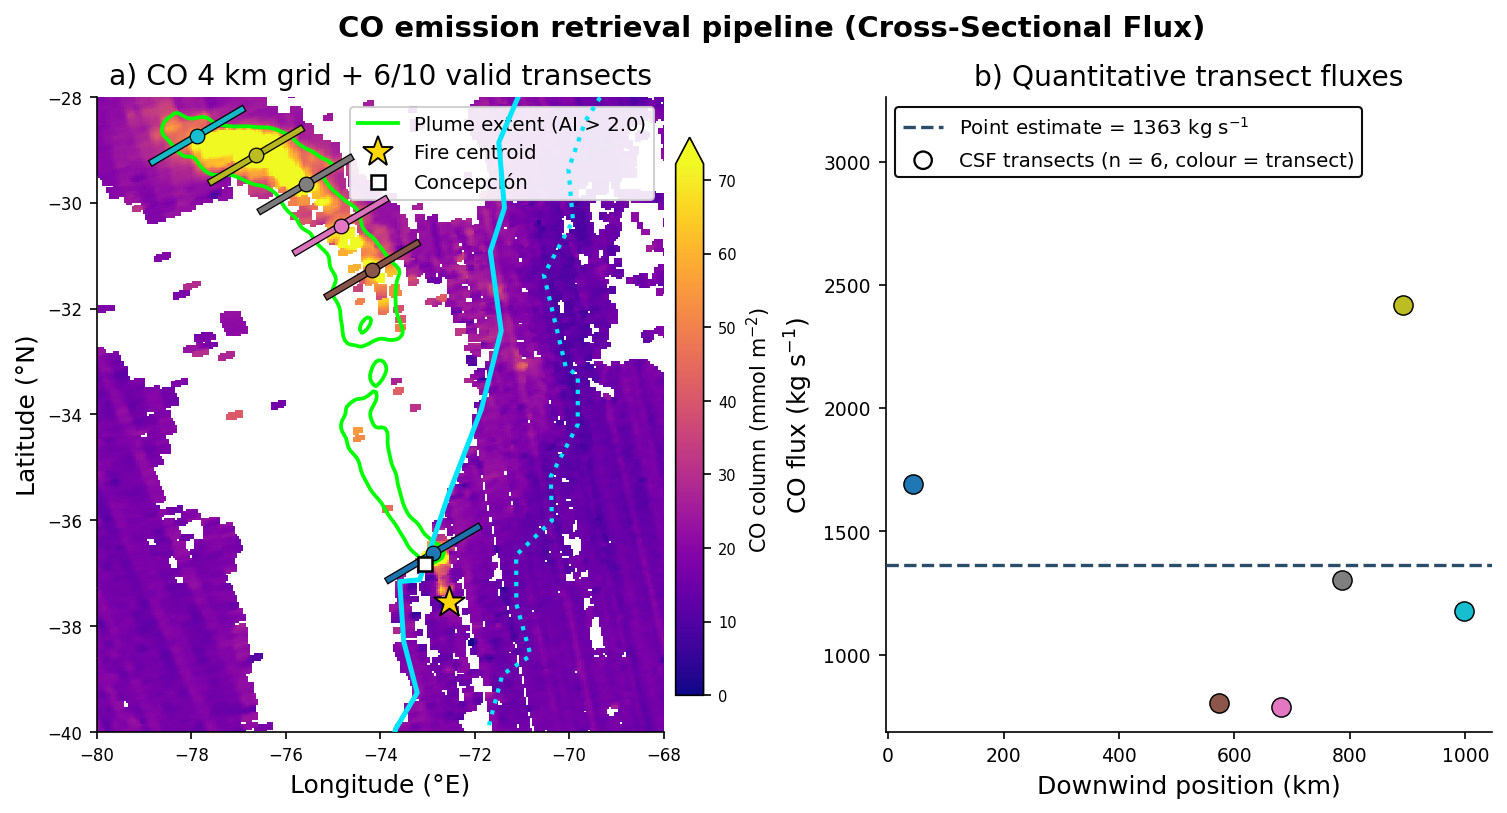

In [10]:
# ── New Figure 1: CO retrieval pipeline (3 columns) ────────────────────────
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import cartopy.io.shapereader as shpreader
from shapely.geometry import box as shapely_box
from matplotlib.lines import Line2D
from src.fire_clustering import load_modis_csv
from src.csf_utils import build_dynamic_transects, compute_local_wind_direction

# Map frame matched to fig01b panel (a)
MAP_LAT_MIN, MAP_LAT_MAX = -40.0, -28.0
MAP_LON_MIN, MAP_LON_MAX = -80.0, -68.0
CONC_LAT, CONC_LON = -36.8269, -73.0497
COAST_C = "#00e5ff"   # cyan — contrasts with the plasma CO field
FIRE_KW = dict(marker="*", s=240, c="gold", edgecolors="black", linewidths=0.9, zorder=10)

# Natural Earth 110m coastline + national borders (same source as fig01b)
_land = list(shpreader.Reader(shpreader.natural_earth(
    resolution="110m", category="physical", name="land")).geometries())
_bord = list(shpreader.Reader(shpreader.natural_earth(
    resolution="110m", category="cultural", name="admin_0_boundary_lines_land")).geometries())
_dbox = shapely_box(MAP_LON_MIN, MAP_LAT_MIN, MAP_LON_MAX, MAP_LAT_MAX)

def _draw_coast(ax, c="0.15", lw=1.6, z=7):
    for g in _land:
        if not g.intersects(_dbox):
            continue
        for p in (g.geoms if g.geom_type == "MultiPolygon" else [g]):
            ax.plot(*p.exterior.xy, color=c, lw=lw, zorder=z)
    for g in _bord:
        if not g.intersects(_dbox):
            continue
        for ln in (g.geoms if g.geom_type == "MultiLineString" else [g]):
            ax.plot(*ln.xy, color=c, lw=lw * 0.85, ls=":", zorder=z)

# MODIS Aqua fires (used by the NO2 figure's panel a)
_fires = load_modis_csv(DATA_DIR / "fire_nrt_M-C61_723973.csv",
                        pd.Timestamp("2026-01-18"), pd.Timestamp("2026-01-18"),
                        lat_min=MAP_LAT_MIN, lat_max=MAP_LAT_MAX,
                        lon_min=MAP_LON_MIN, lon_max=MAP_LON_MAX,
                        min_confidence=0, daytime_only=True, satellite="Aqua")
_frp = _fires["frp"].to_numpy()
_frpn = _frp / _frp.max() if len(_frp) else _frp

def _basemap(ax, coast_color="0.15"):
    _draw_coast(ax, c=coast_color)
    if len(_fires):
        ax.scatter(_fires["longitude"], _fires["latitude"], s=_frpn * 60 + 8,
                   c="white", edgecolors="#c05000", linewidths=0.8, zorder=5)
    ax.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)
    ax.plot(CONC_LON, CONC_LAT, "s", ms=7, mfc="white", mec="black", mew=1.2, zorder=9)
    ax.set_xlim(MAP_LON_MIN, MAP_LON_MAX); ax.set_ylim(MAP_LAT_MIN, MAP_LAT_MAX)
    ax.set_xlabel("Longitude (°E)", fontsize=12)
    ax.set_ylabel("Latitude (°N)", fontsize=12)
    ax.tick_params(labelsize=8)

def _map_legend(ax, coast_color="0.35"):
    ax.legend(fontsize=10, loc="upper right", framealpha=0.88, handles=[
        #ax.scatter([], [], s=30, c="white", edgecolors="#c05000", lw=0.8,
        #           label="MODIS Aqua (size ∝ FRP)"),
        Line2D([0], [0], marker="*", color="none", markerfacecolor="gold",
               markeredgecolor="black", markersize=15, markeredgewidth=0.9,
               label="Dominant cluster"),
        Line2D([0], [0], marker="s", color="none", ms=7, markerfacecolor="white",
               markeredgecolor="black", markeredgewidth=1.2, label="Concepción"),
    ])

# Shared CO colour scale from the 4 km CSF grid
co_grid_mmol = np.where(np.isfinite(co_g), co_g * 1e3, np.nan)
_dom = ((lat_c[:, None] >= MAP_LAT_MIN) & (lat_c[:, None] <= MAP_LAT_MAX) &
        (lon_c[None, :] >= MAP_LON_MIN) & (lon_c[None, :] <= MAP_LON_MAX))
_vmaxg = float(np.nanpercentile(co_grid_mmol[_dom & np.isfinite(co_grid_mmol)], 98))
_conorm = mcolors.Normalize(0, _vmaxg)

# Variant dynamic-transect geometry; categorical colours shared with panel (c)
_scc, _wang, _us, _vs = compute_local_wind_direction(
    u_alh_f, v_alh_f, plume, lat_c, lon_c, n_transects=N_TRANSECTS)
transects_var = build_dynamic_transects(
    lat_c, lon_c, plume, _wang, _us, _vs,
    n_transects=N_TRANSECTS, transect_half_width_km=TRANSECT_HALF_WIDTH_KM,
    sample_spacing_m=CSF_SAMPLE_SPACING_M)
slab_colors = [plt.cm.tab10(k % 10) for k in range(N_TRANSECTS)]

def _co_map_decor(ax):
    _draw_coast(ax, c=COAST_C, lw=2.4)
    ax.scatter(FIRE_LON, FIRE_LAT, **FIRE_KW)
    ax.plot(CONC_LON, CONC_LAT, "s", ms=7, mfc="white", mec="black", mew=1.2, zorder=11)
    ax.set_xlim(MAP_LON_MIN, MAP_LON_MAX); ax.set_ylim(MAP_LAT_MIN, MAP_LAT_MAX)
    ax.set_xlabel("Longitude (°E)", fontsize=12)
    ax.set_ylabel("Latitude (°N)", fontsize=12)
    ax.tick_params(labelsize=8)

fig, (axt, axq) = plt.subplots(1, 2, figsize=(12, 5.5),
                               gridspec_kw={"wspace": 0.30})

# (a) CO 4 km oversampled grid + plume mask + dynamic transects (nb02 Variant).
# Only transects that survived the min_valid_pixels gate are drawn — a
# rejected transect (too few valid deltaCO samples) did not contribute to
# the flux and shouldn't be shown as if it did.
im_b = axt.pcolormesh(lon_c, lat_c, co_grid_mmol, cmap="plasma", norm=_conorm,
                      shading="auto", zorder=1)
_co_map_decor(axt)
# Full plume extent from the AI threshold (boundary-clipped AER_AI).
# Display only — the retrieval mask `plume` is untouched. Drawn exactly like
# fig01 panel (b) (00_mc_parameter_overview): nearest-neighbour resampling of
# the native L2 AI pixels onto a fine regular grid, NOT the cell-averaged
# gridded CSF field.
from scipy.spatial import cKDTree as _CKD_ai
_N_AI = 200
_lon_f = np.linspace(MAP_LON_MIN, MAP_LON_MAX, _N_AI)
_lat_f = np.linspace(MAP_LAT_MIN, MAP_LAT_MAX, _N_AI)
_LGf, _LaGf = np.meshgrid(_lon_f, _lat_f)
_tree_ai = _CKD_ai(np.column_stack([ai_csf["lat"], ai_csf["lon"]]))
_, _nn_ai = _tree_ai.query(np.column_stack([_LaGf.ravel(), _LGf.ravel()]),
                           k=1, workers=-1)
_AI_fine = ai_csf["ai"][_nn_ai].reshape(_N_AI, _N_AI)
# Light Gaussian smoothing of the resampled AI field (display only) so the
# contour doesn't trace individual pixel edges. sigma is in grid cells:
# 1.5 cells x ~6 km/cell ~ 9 km, i.e. ~2 native AER_AI pixels.
from scipy.ndimage import gaussian_filter
_AI_fine_s = gaussian_filter(np.nan_to_num(_AI_fine, nan=0.0), sigma=1.5)
axt.contour(_LGf, _LaGf, _AI_fine_s, levels=[AI_THRESHOLD],
            colors="lime", linewidths=1.8, zorder=4)
for k, t in enumerate(transects_var):
    if not csf_valid[k]:
        continue
    axt.plot(t.positions_lon, t.positions_lat, "-", color=slab_colors[k],
             lw=2.4, alpha=0.97, zorder=6,
             path_effects=[pe.Stroke(linewidth=3.6, foreground="k"), pe.Normal()])
    mid = len(t.positions_lat) // 2
    axt.plot(t.positions_lon[mid], t.positions_lat[mid], "o",
             color=slab_colors[k], ms=7, mec="k", mew=0.6, zorder=7)
cb2 = fig.colorbar(im_b, ax=axt, extend="max", fraction=0.046, pad=0.02)
cb2.set_label(r"CO column (mmol m$^{-2}$)", fontsize=10); cb2.ax.tick_params(labelsize=7)
axt.legend(fontsize=9.5, loc="upper right", framealpha=0.9, handles=[
    Line2D([0], [0], color="lime", lw=1.8, label=f"Plume extent (AI > {AI_THRESHOLD})"),
    Line2D([0], [0], marker="*", color="none", markerfacecolor="gold",
           markeredgecolor="black", markersize=15, markeredgewidth=0.9,
           label="Fire centroid"),
    Line2D([0], [0], marker="s", color="none", ms=7, markerfacecolor="white",
           markeredgecolor="black", markeredgewidth=1.2, label="Concepción"),
])
axt.set_title(rf"a) CO 4 km grid + {n_csf_valid}/{N_TRANSECTS} valid transects",
              fontsize=13.5)

# (b) Quantitative per-transect fluxes — each point coloured by its transect
# (cf. b). Shows the canonical point estimate only (this run's own
# mean-of-valid-transects CSF flux, flux_var_kgs, matching nb02's
# AER_LH-variant headline number); MC posterior omitted by request.
axq.axhline(flux_var_kgs, color=C_CO_E, lw=1.6, ls="--", zorder=3,
            label=f"Point estimate = {flux_var_kgs:.0f} kg s$^{{-1}}$")
for k in range(N_TRANSECTS):
    if not csf_valid[k]:
        continue
    axq.scatter(slab_pos_km[k], t_flux_var_kgs[k], color=slab_colors[k], s=85,
                edgecolor="k", linewidth=0.7, zorder=5)
axq.scatter([], [], facecolors="none", edgecolors="k", linewidths=1.1, s=70,
            label=f"CSF transects (n = {n_csf_valid}, colour = transect)")
axq.set_xlabel("Downwind position (km)", fontsize=12)
axq.set_ylabel(r"CO flux (kg s$^{-1}$)", fontsize=12)
# Headroom so the top-anchored legend box clears the highest transect point.
_cyv = [t_flux_var_kgs[k] for k in range(N_TRANSECTS) if csf_valid[k]]
axq.set_ylim(min(_cyv) - 100, max(_cyv) * 1.35)
axq.legend(loc="upper left", frameon=True, edgecolor="black", framealpha=0.95, fontsize=9.5)
axq.set_title("b) Quantitative transect fluxes", fontsize=13.5)

fig.suptitle("CO emission retrieval pipeline (Cross-Sectional Flux)",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
_out = FIG_DIR / "fig_co_pipeline.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig_no2_pipeline.png


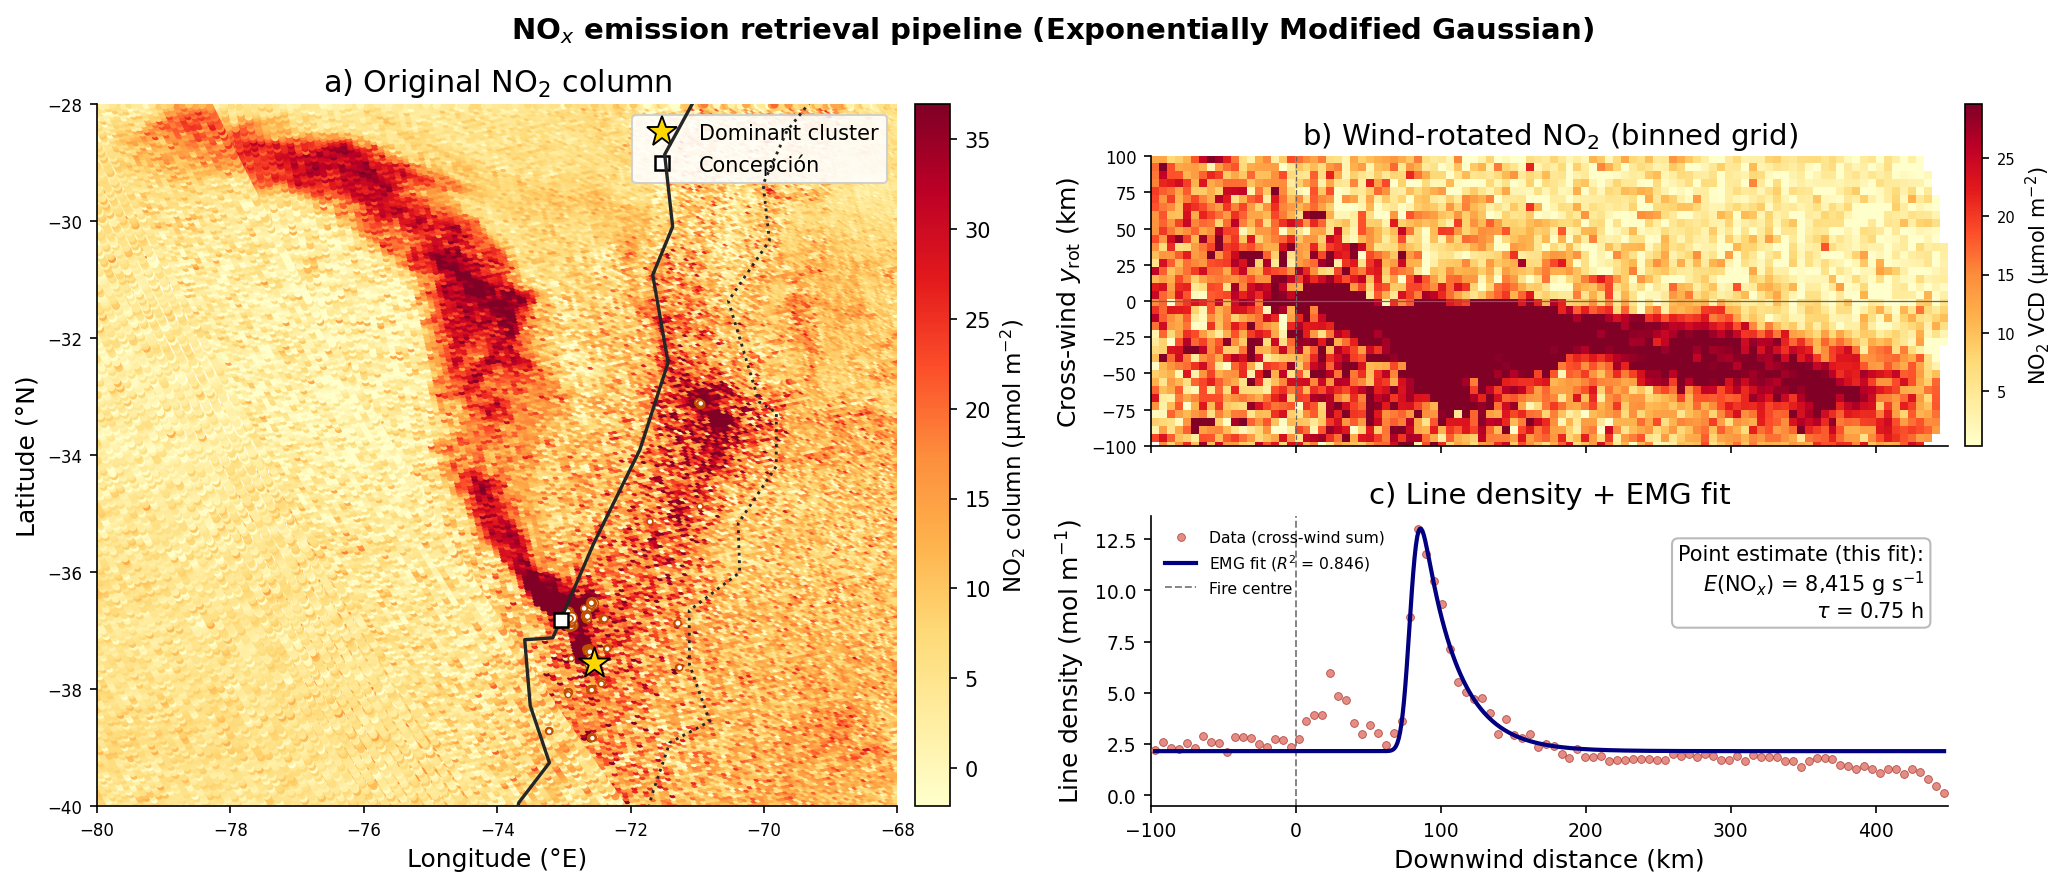

In [11]:
# ── New Figure 2: NO2 retrieval pipeline ───────────────────────────────────
# Layout: left column = original NO2 column (full height); right column split
# into rotated/binned NO2 grid (top) and line density + EMG fit (bottom),
# sharing the same downwind x-axis.
fig = plt.figure(figsize=(13, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.0], height_ratios=[1.0, 0.85],
                      left=0.01, right=0.99, top=0.88, bottom=0.10,
                      wspace=0.23, hspace=0.22)
axo = fig.add_subplot(gs[:, 0])
axr = fig.add_subplot(gs[0, 1])              # b (top)
axe = fig.add_subplot(gs[1, 1], sharex=axr)  # c (bottom) — shares x with b

# (a) Original NO2 column (native L2 pixels, fig01b panel-a frame/size)
no2_umol = no2_data["no2"] * 1e6
_in2 = ((no2_data["lon"] >= MAP_LON_MIN) & (no2_data["lon"] <= MAP_LON_MAX) &
        (no2_data["lat"] >= MAP_LAT_MIN) & (no2_data["lat"] <= MAP_LAT_MAX) &
        np.isfinite(no2_umol))
sc = axo.scatter(no2_data["lon"][_in2], no2_data["lat"][_in2], c=no2_umol[_in2],
                 cmap="YlOrRd", s=15, linewidths=0, rasterized=True, zorder=1,
                 vmin=float(np.nanpercentile(no2_umol[_in2], 5)),
                 vmax=float(np.nanpercentile(no2_umol[_in2], 99)))
cb = fig.colorbar(sc, ax=axo, fraction=0.046, pad=0.02)
cb.set_label(r"NO$_2$ column (µmol m$^{-2}$)", fontsize=11)
cb.ax.tick_params(labelsize=10)
_basemap(axo)
_map_legend(axo)
axo.set_title(r"a) Original NO$_2$ column", fontsize=14.5)

# (b, top-right) Wind-rotated binned NO2 grid (nb03 eda_s4_rotation panel C).
_pos = no2_umol[np.isfinite(no2_umol) & (no2_umol > 0)]
_vmin_r = float(np.nanpercentile(_pos, 1))
_vmax_r = float(np.nanpercentile(_pos, 99))
_grid = np.where(np.isfinite(gmean), gmean * 1e6, np.nan)
# Fill binning gaps by linear interpolation (display only — the EMG fit uses
# the unfilled grid). griddata leaves cells outside the convex hull of valid
# data (swath edge) as NaN, so the interpolation never extrapolates.
from scipy.interpolate import griddata
_XXg, _YYg = np.meshgrid(x_ctrs, y_ctrs, indexing="ij")
_vg = np.isfinite(_grid)
_grid_show = griddata((_XXg[_vg], _YYg[_vg]), _grid[_vg], (_XXg, _YYg),
                      method="linear")
imr = axr.pcolormesh(x_ctrs, y_ctrs, _grid_show.T, cmap="YlOrRd", shading="auto",
                     vmin=_vmin_r, vmax=_vmax_r)
axr.axhline(0, color="0.4", lw=0.6); axr.axvline(0, color="0.4", lw=0.6, ls="--")
cbr = fig.colorbar(imr, ax=axr, fraction=0.05, pad=0.02)
cbr.set_label(r"NO$_2$ VCD (µmol m$^{-2}$)", fontsize=10)
cbr.ax.tick_params(labelsize=7)
axr.set_ylabel(r"Cross-wind $y_{\mathrm{rot}}$ (km)", fontsize=12)
axr.set_ylim(-100, 100)
axr.set_box_aspect(200 / 550)        # square 5.5 km cells (height/width = y/x range)
axr.set_anchor("S")                  # sit at the bottom of its cell, next to c
axr.tick_params(labelsize=8, labelbottom=False)   # hide x labels (c carries them)
axr.set_title(r"b) Wind-rotated NO$_2$ (binned grid)", fontsize=14)

# (c, bottom-right) Downwind line density + EMG fit (= Fig 2a)
xd = np.linspace(x_fit.min(), x_fit.max(), 600)
axe.scatter(x_fit, y_fit, s=14, color=C_NOX, edgecolor=C_NOX_E, linewidth=0.4,
            alpha=0.85, zorder=3, label="Data (cross-wind sum)")
axe.plot(xd, emg(xd, *pmed), "-", color="navy", lw=2, zorder=4,
         label=f"EMG fit ($R^2$ = {emg_r2:.3f})")
axe.axvline(0, color="gray", lw=0.9, ls="--", zorder=1, label="Fire centre")
axe.set_xlabel("Downwind distance (km)", fontsize=12)
axe.set_ylabel(r"Line density (mol m$^{-1}$)", fontsize=12)
axe.set_xlim(-100, 450)              # shared -> also sets panel b's x-axis
axe.legend(loc="upper left", frameon=False, fontsize=7.5)
axe.text(0.97, 0.90,
         "Point estimate (this fit):\n"
         rf"$E$(NO$_x$) = {E_nox_g_s:,.0f} g s$^{{-1}}$" + "\n"
         rf"$\tau$ = {tau_h:.2f} h",
         transform=axe.transAxes, ha="right", va="top", fontsize=10,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
axe.set_title("c) Line density + EMG fit", fontsize=14)

# Give panel c the SAME width reservation as b's colorbar, so the shared
# x-axis lines up (dummy colorbar, hidden).
_cb_dummy = fig.colorbar(imr, ax=axe, fraction=0.05, pad=0.02)
_cb_dummy.ax.set_visible(False)

fig.suptitle(r"NO$_x$ emission retrieval pipeline (Exponentially Modified Gaussian)",
             fontsize=14, fontweight="bold")
_out = FIG_DIR / "fig_no2_pipeline.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print("saved", _out)
plt.show()

## Appendix Figure — Monte-Carlo observation-informed priors

Two-panel appendix figure for the MC parameter table (Table~3 / `tab:mc_params`): **(a)** the injection-pressure prior (the AER\_LH matched-pixel distribution + Gaussian KDE, formerly Figure 1c) and **(b)** the FRP-weighted 2-D source-location prior. Priors are built with the identical parameters used by nb07/nb08 and diagnosed in nb10 (`10_error_mc_parameter_distributions`).

saved /Users/maperezc/Downloads/wildfires/paper_staging/figures/figS3_mc_priors.png | pressure: mean=882 median=898 IQR=73 n=99 | spatial: n=146


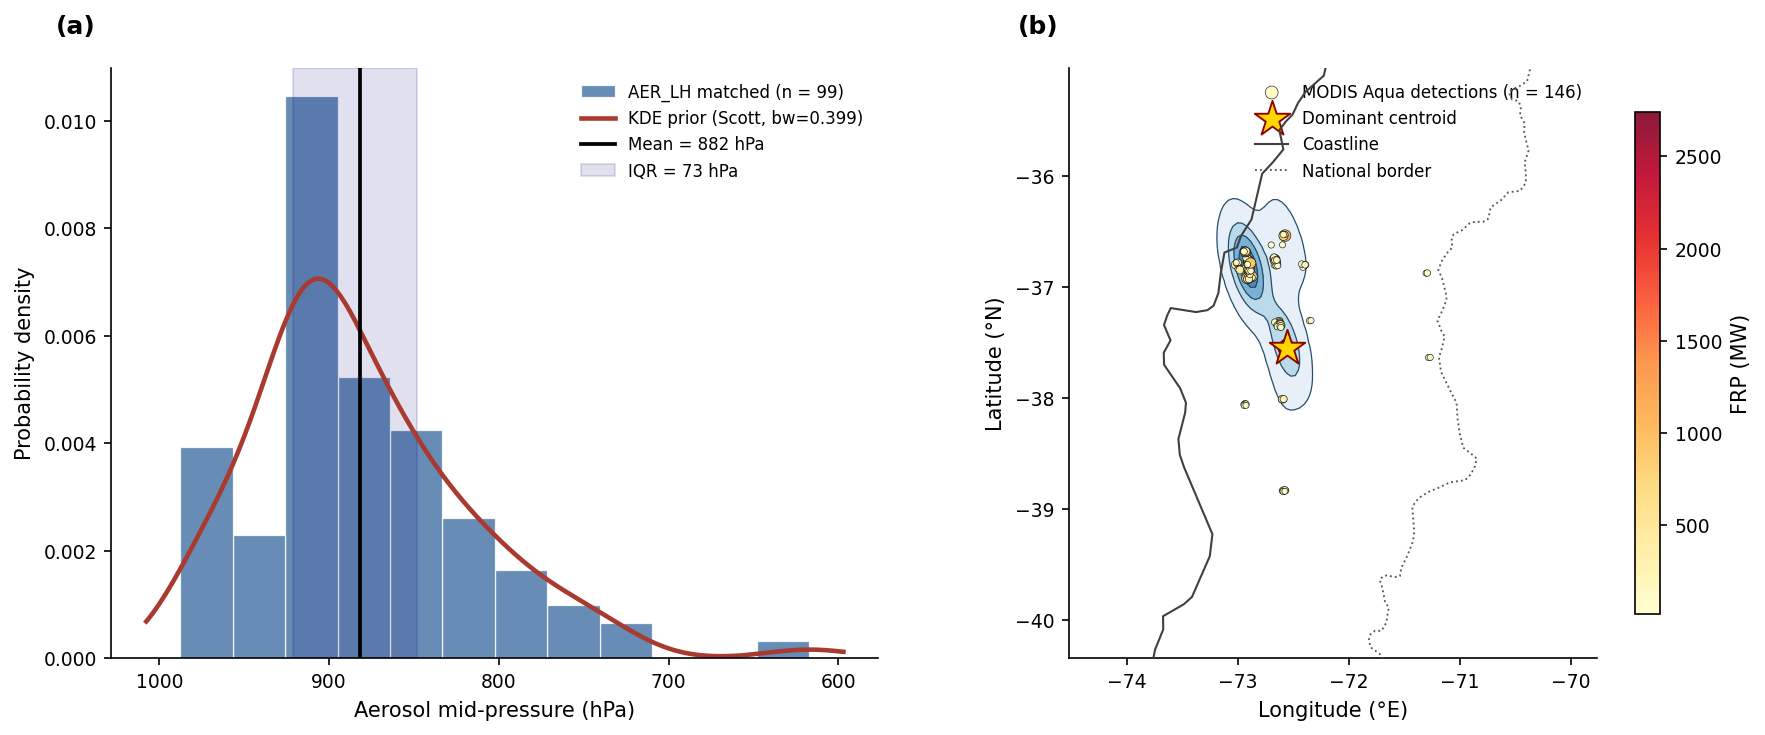

In [12]:
# ── Appendix figure: MC observation-informed priors (pressure + source loc.) ──
# (a) injection-pressure prior  = old Fig 1c (AER_LH matched pixels + KDE)
# (b) source-location prior      = FRP-weighted 2-D KDE (nb10 spatial_panel logic)
from scipy.stats import gaussian_kde
from src.wind_helpers import match_alh_plume_pressures
from src import error_estimation as ee
import cartopy.io.shapereader as shpreader
from shapely.geometry import box as shapely_box
_ne_land = list(shpreader.Reader(shpreader.natural_earth(
    resolution="50m", category="physical", name="land")).geometries())
_ne_bord = list(shpreader.Reader(shpreader.natural_earth(
    resolution="50m", category="cultural", name="admin_0_boundary_lines_land")).geometries())

# --- (a) injection-pressure prior: reuse the same ai_data/alh_data as Fig 2/S2 ---
_m = match_alh_plume_pressures(
    ai_raw=ai_data["ai"], ai_lat=ai_data["lat"], ai_lon=ai_data["lon"],
    alh_pres_raw=alh_data["alh_pres"], alh_lat=alh_data["lat"], alh_lon=alh_data["lon"],
    fire_lat=FIRE_LAT, fire_lon=FIRE_LON, ai_threshold=AI_THRESHOLD, radius_km=450.0)
pres = np.asarray(_m["pres_hpa"], float); pres = pres[np.isfinite(pres)]
p_mean = float(pres.mean()); p_med = float(np.median(pres))
pq25, pq75 = np.percentile(pres, [25, 75]); p_iqr = pq75 - pq25
kde_p = gaussian_kde(pres, bw_method="scott")

# --- (b) source-location prior: FRP-weighted 2-D KDE (same params as nb07/08/10) ---
ck = ee.build_centroid_kde(
    DATA_DIR / "fire_nrt_M-C61_723973.csv", "2026-01-18", FIRE_LAT, FIRE_LON,
    local_radius_km=200.0, min_confidence=75, satellite="Aqua", daynight="D")
slats, slons, sfrp, kde_s = ck["lats"], ck["lons"], ck["frp"], ck["kde"]

fig, (axp, axs) = plt.subplots(1, 2, figsize=(12, 5))

# (a) injection-pressure prior
nbp_ = max(12, int(np.sqrt(len(pres))))
axp.hist(pres, bins=nbp_, color=C_CO, edgecolor="white", linewidth=0.6, alpha=0.85,
         density=True, label=f"AER_LH matched (n = {len(pres)})")
xx = np.linspace(pres.min() - 20, pres.max() + 20, 400)
axp.plot(xx, kde_p(xx), color=C_NOX_E, lw=2.2, label=f"KDE prior (Scott, bw={kde_p.factor:.3f})")
axp.axvline(p_mean, color=C_MED, lw=1.8, ls="-", label=f"Mean = {p_mean:.0f} hPa")
axp.axvspan(pq25, pq75, color="navy", alpha=0.12, label=f"IQR = {p_iqr:.0f} hPa")
axp.set_xlabel("Aerosol mid-pressure (hPa)"); axp.set_ylabel("Probability density")
axp.invert_xaxis()   # low pressure (high altitude) to the right
axp.legend(loc="upper right", frameon=False, fontsize=8)
panel_label(axp, "(a)")

# (b) source-location FRP-weighted 2-D KDE
lat_g = np.linspace(slats.min() - 1.5, slats.max() + 1.5, 120)
lon_g = np.linspace(slons.min() - 1.5, slons.max() + 1.5, 120)
LON_G, LAT_G = np.meshgrid(lon_g, lat_g)
kv = kde_s(np.vstack([LAT_G.ravel(), LON_G.ravel()])).reshape(len(lat_g), len(lon_g))
kmax = float(kv.max())
levels = list(np.linspace(kmax * 0.05, kmax, 5))
axs.contourf(LON_G, LAT_G, kv, levels=levels, cmap="Blues", alpha=0.7)
axs.contour(LON_G, LAT_G, kv, levels=levels[:-1], colors=[C_CO_E], linewidths=0.6)
sc = axs.scatter(slons, slats, c=sfrp, cmap="YlOrRd", s=8 + 60 * (sfrp / sfrp.max()),
                 alpha=0.9, edgecolors="k", linewidths=0.3, zorder=5,
                 label=f"MODIS Aqua detections (n = {len(slats)})")
plt.colorbar(sc, ax=axs, label="FRP (MW)", shrink=0.85)
axs.scatter(FIRE_LON, FIRE_LAT, marker="*", s=320, c="gold", edgecolors="darkred",
            lw=0.9, zorder=10, label="Dominant centroid")
# coastline + national borders (Natural Earth 50m), clipped to panel extent
_bb = shapely_box(lon_g.min(), lat_g.min(), lon_g.max(), lat_g.max())
for _g in _ne_land:
    if not _g.intersects(_bb):
        continue
    for _p in (_g.geoms if _g.geom_type == "MultiPolygon" else [_g]):
        axs.plot(*_p.exterior.xy, color="0.25", lw=1.0, zorder=6)
for _g in _ne_bord:
    if not _g.intersects(_bb):
        continue
    for _ln in (_g.geoms if _g.geom_type == "MultiLineString" else [_g]):
        axs.plot(*_ln.xy, color="0.35", lw=0.9, ls=":", zorder=6)
axs.set_xlim(lon_g.min(), lon_g.max()); axs.set_ylim(lat_g.min(), lat_g.max())
axs.set_xlabel("Longitude (°E)"); axs.set_ylabel("Latitude (°N)")
from matplotlib.lines import Line2D
_h, _l = axs.get_legend_handles_labels()
_h += [Line2D([0],[0], color="0.25", lw=1.0, label="Coastline"),
       Line2D([0],[0], color="0.35", lw=0.9, ls=":", label="National border")]
axs.set_aspect("equal"); axs.legend(handles=_h, loc="upper right", frameon=False, fontsize=8)
panel_label(axs, "(b)")

fig.tight_layout()
_out = FIG_DIR / "figS3_mc_priors.png"
fig.savefig(_out, dpi=300, bbox_inches="tight")
print(f"saved {_out} | pressure: mean={p_mean:.0f} median={p_med:.0f} IQR={p_iqr:.0f} n={len(pres)}"
      f" | spatial: n={len(slats)}")
plt.show()
